# 🧪 Illustration des Méthodes STOCSY et RANSY pour l'Annotation RMN 1H

Ce notebook illustre les deux méthodes statistiques clés utilisées dans le pipeline d'annotation RMN 1H :

## **STOCSY** (Statistical TOtal Correlation SpectroscopY)
- Méthode de corrélation statistique qui identifie les signaux appartenant à la même molécule
- Basée sur le coefficient de corrélation de Pearson entre un pic "driver" et tous les autres points spectraux
- Les pics fortement corrélés (|r| > seuil) proviennent probablement de la même molécule

## **RANSY** (Ratio Analysis of NMR SpectroscopY)
- Méthode complémentaire basée sur la stabilité des ratios d'intensité
- Calcule le coefficient de variation (CV) des ratios d'intensité entre pics
- Les pics avec des ratios stables (CV faible) appartiennent à la même molécule

---
**Référence Code R:** `annotation_1H.R` - Pipeline Match → STOCSY → RANSY

## 1. Import des Bibliothèques

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy import stats
from scipy.ndimage import gaussian_filter1d
import warnings
warnings.filterwarnings('ignore')

# Configuration du style des graphiques
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['legend.fontsize'] = 10

# Palette de couleurs personnalisée pour STOCSY
stocsy_cmap = LinearSegmentedColormap.from_list('stocsy', 
    ['#0000FF', '#00BFFF', '#00FF00', '#FFFF00', '#FF8000', '#FF0000'])

print("✅ Bibliothèques importées avec succès")

✅ Bibliothèques importées avec succès


## 2. Génération de Données Spectrales RMN Simulées

Nous simulons une matrice spectrale typique avec :
- **50 échantillons** (lignes) - représentant différentes mesures/réplicats
- **1000 points ppm** (colonnes) - axe chimique de 0 à 10 ppm
- **3 molécules** avec des pics caractéristiques :
  - **Molécule A** (rouge) : pics à 1.2, 2.4, 3.8 ppm - intensités corrélées
  - **Molécule B** (vert) : pics à 4.5, 6.2, 7.8 ppm - intensités corrélées
  - **Molécule C** (bleu) : pics à 5.1, 8.5, 9.2 ppm - intensités corrélées
- Bruit de fond gaussien pour simuler les conditions expérimentales réelles

In [16]:
np.random.seed(42)

# Paramètres de simulation
n_samples = 50      # Nombre d'échantillons (mesures)
n_points = 1000     # Points spectraux
ppm_range = np.linspace(0, 10, n_points)  # Axe ppm

def gaussian_peak(ppm, center, width=0.08, amplitude=1.0):
    """Génère un pic gaussien centré à 'center' ppm"""
    return amplitude * np.exp(-((ppm - center)**2) / (2 * width**2))

# Définition des molécules avec leurs pics caractéristiques
molecules = {
    'Molécule A': {'peaks': [1.2, 2.4, 3.8], 'color': '#E74C3C', 'ratios': [1.0, 0.7, 0.4]},
    'Molécule B': {'peaks': [4.5, 6.2, 7.8], 'color': '#27AE60', 'ratios': [1.0, 0.5, 0.3]},
    'Molécule C': {'peaks': [5.1, 8.5, 9.2], 'color': '#3498DB', 'ratios': [1.0, 0.8, 0.6]}
}

# Génération de la matrice spectrale
spectrum_matrix = np.zeros((n_samples, n_points))

# Concentrations variables pour chaque molécule dans chaque échantillon
concentrations = {}
for mol_name in molecules:
    # Concentration entre 0.5 et 2.0 avec variation aléatoire
    concentrations[mol_name] = np.random.uniform(0.5, 2.0, n_samples)

# Construction des spectres
for i in range(n_samples):
    spectrum = np.zeros(n_points)
    
    for mol_name, mol_data in molecules.items():
        conc = concentrations[mol_name][i]
        for peak_idx, peak_ppm in enumerate(mol_data['peaks']):
            # Intensité = concentration × ratio relatif du pic
            intensity = conc * mol_data['ratios'][peak_idx]
            # Légère variation du ratio (±5%) pour simuler bruit expérimental
            intensity *= np.random.uniform(0.95, 1.05)
            spectrum += gaussian_peak(ppm_range, peak_ppm, amplitude=intensity)
    
    # Ajout de bruit gaussien
    noise = np.random.normal(0, 0.02, n_points)
    spectrum += np.abs(noise)
    
    spectrum_matrix[i] = spectrum

# Création du DataFrame
df_spectra = pd.DataFrame(spectrum_matrix, columns=[f'{p:.4f}' for p in ppm_range])
df_spectra.insert(0, 'sample_id', [f'Sample_{i+1}' for i in range(n_samples)])

print(f"✅ Matrice spectrale générée: {n_samples} échantillons × {n_points} points ppm")
print(f"   Plage ppm: {ppm_range.min():.1f} - {ppm_range.max():.1f}")
print(f"   Molécules simulées: {list(molecules.keys())}")

✅ Matrice spectrale générée: 50 échantillons × 1000 points ppm
   Plage ppm: 0.0 - 10.0
   Molécules simulées: ['Molécule A', 'Molécule B', 'Molécule C']


## 3. Visualisation des Spectres RMN Bruts

Affichage de la matrice spectrale complète avec :
- Spectres superposés colorés par échantillon
- Indication des pics de chaque molécule
- Vue d'ensemble de la variabilité inter-échantillons

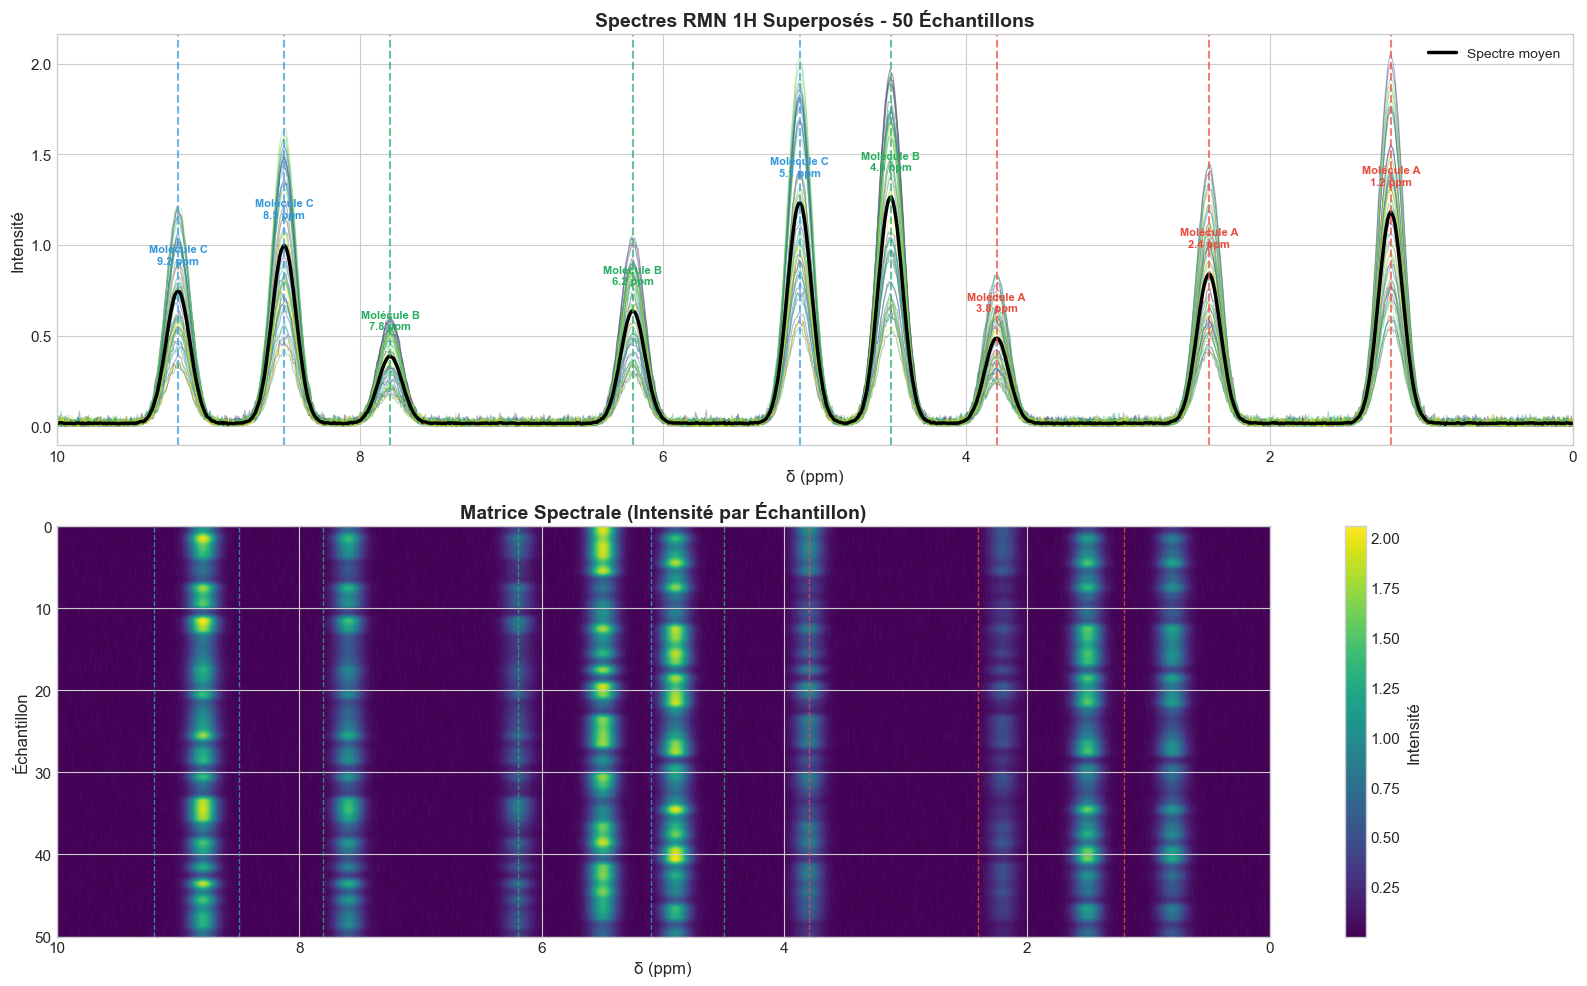

📊 Figure 1: Vue d'ensemble des spectres RMN avec variabilité inter-échantillons


In [17]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10))

# === Subplot 1: Spectres superposés ===
ax1 = axes[0]
colors = plt.cm.viridis(np.linspace(0, 1, n_samples))
for i in range(n_samples):
    ax1.plot(ppm_range, spectrum_matrix[i], color=colors[i], alpha=0.4, linewidth=0.8)

# Spectre moyen en noir épais
mean_spectrum = spectrum_matrix.mean(axis=0)
ax1.plot(ppm_range, mean_spectrum, 'k-', linewidth=2.5, label='Spectre moyen')

# Annotation des pics par molécule
for mol_name, mol_data in molecules.items():
    for peak in mol_data['peaks']:
        peak_idx = np.argmin(np.abs(ppm_range - peak))
        ax1.axvline(x=peak, color=mol_data['color'], linestyle='--', alpha=0.7, linewidth=1.5)
        ax1.annotate(f'{mol_name}\n{peak} ppm', xy=(peak, mean_spectrum[peak_idx] + 0.15),
                    fontsize=8, ha='center', color=mol_data['color'], fontweight='bold')

ax1.set_xlabel('δ (ppm)')
ax1.set_ylabel('Intensité')
ax1.set_title('Spectres RMN 1H Superposés - 50 Échantillons', fontsize=14, fontweight='bold')
ax1.set_xlim(0, 10)
ax1.invert_xaxis()  # Convention RMN: ppm décroissant
ax1.legend(loc='upper right')

# === Subplot 2: Heatmap de la matrice spectrale ===
ax2 = axes[1]
im = ax2.imshow(spectrum_matrix, aspect='auto', cmap='viridis', 
                extent=[ppm_range.max(), ppm_range.min(), n_samples, 0])
ax2.set_xlabel('δ (ppm)')
ax2.set_ylabel('Échantillon')
ax2.set_title('Matrice Spectrale (Intensité par Échantillon)', fontsize=14, fontweight='bold')
cbar = plt.colorbar(im, ax=ax2, label='Intensité')

# Lignes verticales pour les pics
for mol_name, mol_data in molecules.items():
    for peak in mol_data['peaks']:
        ax2.axvline(x=peak, color=mol_data['color'], linestyle='--', alpha=0.8, linewidth=1)

plt.tight_layout()
plt.savefig('figures/01_raw_nmr_spectra.png', dpi=150, bbox_inches='tight')
plt.show()

print("📊 Figure 1: Vue d'ensemble des spectres RMN avec variabilité inter-échantillons")

## 4. STOCSY - Implémentation et Visualisation

### Principe STOCSY
La méthode STOCSY calcule la **corrélation de Pearson** entre l'intensité d'un pic "driver" (pivot) et tous les autres points du spectre, à travers tous les échantillons.

$$r_{xy} = \frac{\sum_{i=1}^{n}(x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum_{i=1}^{n}(x_i - \bar{x})^2} \cdot \sqrt{\sum_{i=1}^{n}(y_i - \bar{y})^2}}$$

**Interprétation:**
- $|r| > 0.8$ → Pics fortement corrélés (même molécule probable)
- $|r| < 0.5$ → Pics faiblement corrélés (molécules différentes)

Le code R correspondant (`calculer_STOCSY`) utilise exactement cette approche.

In [18]:
def calculate_stocsy(spectrum_matrix, ppm_range, driver_ppm, r_threshold=0.8):
    """
    Calcule STOCSY à partir d'un pic driver.
    
    Paramètres:
    -----------
    spectrum_matrix : np.array (n_samples, n_points)
        Matrice d'intensité spectrale
    ppm_range : np.array
        Valeurs ppm correspondantes
    driver_ppm : float
        Position ppm du pic driver
    r_threshold : float
        Seuil de corrélation minimum (|r| >= r_threshold)
    
    Retourne:
    ---------
    correlations : np.array
        Coefficients de corrélation pour chaque point ppm
    significant_mask : np.array (bool)
        Masque des pics significativement corrélés
    """
    # Trouver l'indice du driver
    driver_idx = np.argmin(np.abs(ppm_range - driver_ppm))
    driver_signal = spectrum_matrix[:, driver_idx]
    
    # Calculer la corrélation avec chaque point du spectre
    correlations = np.zeros(len(ppm_range))
    for i in range(len(ppm_range)):
        if np.std(spectrum_matrix[:, i]) > 0:
            correlations[i] = np.corrcoef(driver_signal, spectrum_matrix[:, i])[0, 1]
        else:
            correlations[i] = 0
    
    # Masque des pics significatifs
    significant_mask = np.abs(correlations) >= r_threshold
    
    return correlations, significant_mask

# Appliquer STOCSY avec le pic à 1.2 ppm (Molécule A) comme driver
driver_ppm_A = 1.2
correlations_A, significant_A = calculate_stocsy(spectrum_matrix, ppm_range, driver_ppm_A, r_threshold=0.8)

print(f"✅ STOCSY calculé avec driver à {driver_ppm_A} ppm (Molécule A)")
print(f"   Pics avec |r| ≥ 0.8: {significant_A.sum()} points")

✅ STOCSY calculé avec driver à 1.2 ppm (Molécule A)
   Pics avec |r| ≥ 0.8: 118 points


### 🔬 Principe Fondamental de STOCSY: La Covariance Inter-Échantillons

**Idée clé:** Les signaux appartenant à la **même molécule** varient **ensemble** d'un échantillon à l'autre :

- 📈 Si la concentration de la molécule **augmente** → **TOUS** ses pics augmentent
- 📉 Si la concentration **diminue** → **TOUS** ses pics diminuent proportionnellement

Cette covariance naturelle est la base de STOCSY. Les pics de molécules **différentes** varient **indépendamment** car leurs concentrations ne sont pas liées.

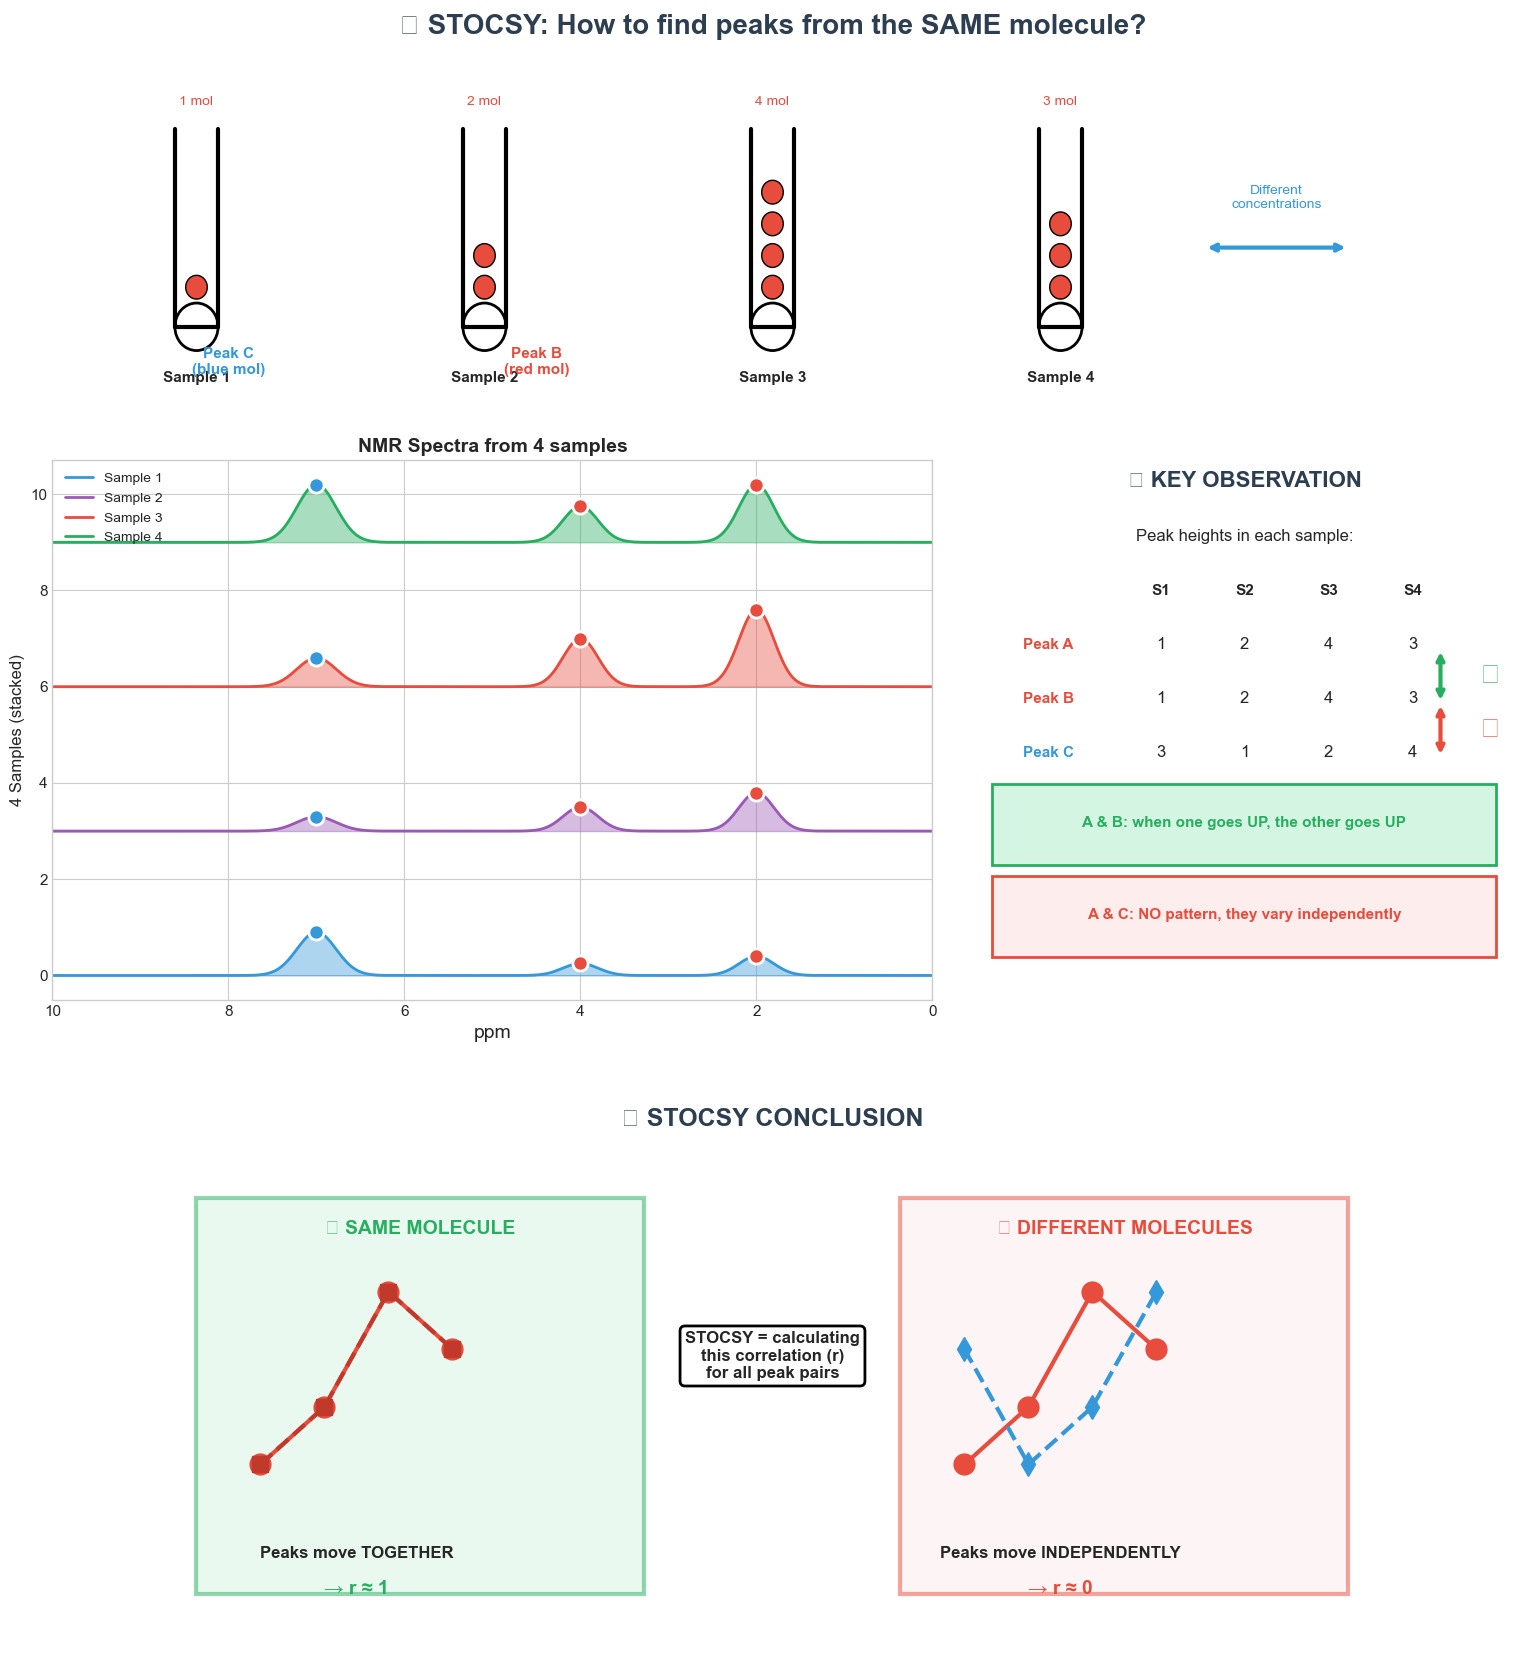


📚 STOCSY - THE SIMPLE IDEA:
   • We have MANY samples with different concentrations
   • Each sample → one NMR spectrum
   • If Peak A goes UP when Peak B goes UP (across samples)
   • → They belong to the SAME molecule!
   • STOCSY measures this 'going together' = correlation


In [34]:
# === ILLUSTRATION STOCSY - TRÈS SIMPLE ET VISUELLE ===

fig = plt.figure(figsize=(16, 18))

# ============ PARTIE 1: LE CONTEXTE ============
ax1 = fig.add_axes([0.05, 0.75, 0.9, 0.22])
ax1.axis('off')
ax1.set_xlim(0, 20)
ax1.set_ylim(0, 5)

ax1.text(10, 4.7, '🧪 STOCSY: How to find peaks from the SAME molecule?', 
        fontsize=20, fontweight='bold', ha='center', color='#2C3E50')

# Dessiner 4 tubes/échantillons avec différentes quantités de molécule rouge
tube_x = [2, 6, 10, 14]
tube_labels = ['Sample 1', 'Sample 2', 'Sample 3', 'Sample 4']
mol_counts = [1, 2, 4, 3]  # Nombre de molécules dans chaque échantillon

for x, label, n_mol in zip(tube_x, tube_labels, mol_counts):
    # Tube
    ax1.plot([x-0.3, x-0.3], [1, 3.5], 'k-', linewidth=3)
    ax1.plot([x+0.3, x+0.3], [1, 3.5], 'k-', linewidth=3)
    ax1.plot([x-0.3, x+0.3], [1, 1], 'k-', linewidth=3)
    ax1.add_patch(plt.Circle((x, 1), 0.3, facecolor='white', edgecolor='black', linewidth=2))
    
    # Molécules rouges (petits cercles)
    for i in range(n_mol):
        y_mol = 1.5 + i * 0.4
        ax1.add_patch(plt.Circle((x, y_mol), 0.15, facecolor='#E74C3C', edgecolor='black'))
    
    ax1.text(x, 0.3, label, ha='center', fontsize=11, fontweight='bold')
    ax1.text(x, 3.8, f'{n_mol} mol', ha='center', fontsize=10, color='#E74C3C')

# Flèche "different concentrations"
ax1.annotate('', xy=(16, 2), xytext=(18, 2),
            arrowprops=dict(arrowstyle='<->', color='#3498DB', lw=3))
ax1.text(17, 2.5, 'Different\nconcentrations', ha='center', fontsize=10, color='#3498DB')

# ============ PARTIE 2: LES SPECTRES ============
ax2 = fig.add_axes([0.05, 0.42, 0.55, 0.30])

ppm = np.linspace(0, 10, 500)

# Intensités des pics pour chaque échantillon
# Molécule rouge: pics à 2 et 4 ppm (corrélés)
# Molécule bleue: pic à 7 ppm (indépendant)
specs_data = [
    {'mol_A': 1, 'mol_B': 3},   # Sample 1
    {'mol_A': 2, 'mol_B': 1},   # Sample 2
    {'mol_A': 4, 'mol_B': 2},   # Sample 3
    {'mol_A': 3, 'mol_B': 4},   # Sample 4
]

colors_samples = ['#3498DB', '#9B59B6', '#E74C3C', '#27AE60']
offsets = [0, 3, 6, 9]

for i, (data, color, offset, label) in enumerate(zip(specs_data, colors_samples, offsets, tube_labels)):
    # Créer le spectre
    spec = offset + data['mol_A'] * 0.4 * np.exp(-((ppm-2)**2)/0.08) + \
           data['mol_A'] * 0.25 * np.exp(-((ppm-4)**2)/0.08) + \
           data['mol_B'] * 0.3 * np.exp(-((ppm-7)**2)/0.1)
    
    ax2.fill_between(ppm, offset, spec, alpha=0.4, color=color)
    ax2.plot(ppm, spec, color=color, linewidth=2, label=label)
    
    # Marquer les pics avec leur hauteur
    h_peak1 = data['mol_A'] * 0.4
    h_peak2 = data['mol_A'] * 0.25
    h_peak3 = data['mol_B'] * 0.3
    
    ax2.scatter([2], [offset + h_peak1], s=120, c='#E74C3C', zorder=5, edgecolor='white', linewidth=2)
    ax2.scatter([4], [offset + h_peak2], s=120, c='#E74C3C', zorder=5, edgecolor='white', linewidth=2)
    ax2.scatter([7], [offset + h_peak3], s=120, c='#3498DB', zorder=5, edgecolor='white', linewidth=2)

ax2.set_xlim(0, 10)
ax2.invert_xaxis()
ax2.set_xlabel('ppm', fontsize=14)
ax2.set_ylabel('4 Samples (stacked)', fontsize=12)
ax2.set_title('NMR Spectra from 4 samples', fontsize=14, fontweight='bold')
ax2.legend(loc='upper left', fontsize=10)

# Annotations sur les pics
ax2.annotate('Peak A\n(red mol)', xy=(2, 11), xytext=(1, 12.5),
            fontsize=11, color='#E74C3C', fontweight='bold', ha='center')
ax2.annotate('Peak B\n(red mol)', xy=(4, 10.5), xytext=(4.5, 12.5),
            fontsize=11, color='#E74C3C', fontweight='bold', ha='center')
ax2.annotate('Peak C\n(blue mol)', xy=(7, 10), xytext=(8, 12.5),
            fontsize=11, color='#3498DB', fontweight='bold', ha='center')

# ============ PARTIE 3: LE PRINCIPE CLÉ ============
ax3 = fig.add_axes([0.62, 0.42, 0.35, 0.30])
ax3.axis('off')
ax3.set_xlim(0, 10)
ax3.set_ylim(0, 10)

ax3.text(5, 9.5, '💡 KEY OBSERVATION', fontsize=16, fontweight='bold', ha='center', color='#2C3E50')

# Tableau simplifié
ax3.text(5, 8.5, 'Peak heights in each sample:', fontsize=12, ha='center')

# Header
ax3.text(1.5, 7.5, '', fontsize=10, ha='center')
ax3.text(3.5, 7.5, 'S1', fontsize=11, ha='center', fontweight='bold')
ax3.text(5, 7.5, 'S2', fontsize=11, ha='center', fontweight='bold')
ax3.text(6.5, 7.5, 'S3', fontsize=11, ha='center', fontweight='bold')
ax3.text(8, 7.5, 'S4', fontsize=11, ha='center', fontweight='bold')

# Peak A (red)
ax3.text(1.5, 6.5, 'Peak A', fontsize=11, ha='center', color='#E74C3C', fontweight='bold')
ax3.text(3.5, 6.5, '1', fontsize=12, ha='center')
ax3.text(5, 6.5, '2', fontsize=12, ha='center')
ax3.text(6.5, 6.5, '4', fontsize=12, ha='center')
ax3.text(8, 6.5, '3', fontsize=12, ha='center')

# Peak B (red)
ax3.text(1.5, 5.5, 'Peak B', fontsize=11, ha='center', color='#E74C3C', fontweight='bold')
ax3.text(3.5, 5.5, '1', fontsize=12, ha='center')
ax3.text(5, 5.5, '2', fontsize=12, ha='center')
ax3.text(6.5, 5.5, '4', fontsize=12, ha='center')
ax3.text(8, 5.5, '3', fontsize=12, ha='center')

# Peak C (blue) 
ax3.text(1.5, 4.5, 'Peak C', fontsize=11, ha='center', color='#3498DB', fontweight='bold')
ax3.text(3.5, 4.5, '3', fontsize=12, ha='center')
ax3.text(5, 4.5, '1', fontsize=12, ha='center')
ax3.text(6.5, 4.5, '2', fontsize=12, ha='center')
ax3.text(8, 4.5, '4', fontsize=12, ha='center')

# Flèches de corrélation
ax3.annotate('', xy=(8.5, 6.5), xytext=(8.5, 5.5),
            arrowprops=dict(arrowstyle='<->', color='#27AE60', lw=3))
ax3.text(9.2, 6, '✓', fontsize=20, color='#27AE60', va='center')

ax3.annotate('', xy=(8.5, 5.5), xytext=(8.5, 4.5),
            arrowprops=dict(arrowstyle='<->', color='#E74C3C', lw=3))
ax3.text(9.2, 5, '✗', fontsize=20, color='#E74C3C', va='center')

# Explication
rect1 = plt.Rectangle((0.5, 2.5), 9, 1.5, facecolor='#D5F5E3', edgecolor='#27AE60', linewidth=2)
ax3.add_patch(rect1)
ax3.text(5, 3.2, 'A & B: when one goes UP, the other goes UP', fontsize=11, ha='center', fontweight='bold', color='#27AE60')

rect2 = plt.Rectangle((0.5, 0.8), 9, 1.5, facecolor='#FDEDEC', edgecolor='#E74C3C', linewidth=2)
ax3.add_patch(rect2)
ax3.text(5, 1.5, 'A & C: NO pattern, they vary independently', fontsize=11, ha='center', fontweight='bold', color='#E74C3C')

# ============ PARTIE 4: CONCLUSION VISUELLE ============
ax4 = fig.add_axes([0.1, 0.05, 0.8, 0.32])
ax4.axis('off')
ax4.set_xlim(0, 20)
ax4.set_ylim(0, 8)

ax4.text(10, 7.5, '🎯 STOCSY CONCLUSION', fontsize=18, fontweight='bold', ha='center', color='#2C3E50')

# Côté gauche: SAME molecule
ax4.add_patch(plt.Rectangle((1, 1), 7, 5.5, facecolor='#D5F5E3', edgecolor='#27AE60', linewidth=3, alpha=0.5))
ax4.text(4.5, 6, '✓ SAME MOLECULE', fontsize=14, fontweight='bold', ha='center', color='#27AE60')

# Graphique simplifié peaks A et B
x_pts = [2, 3, 4, 5]
y_A = [1, 2, 4, 3]
y_B = [1, 2, 4, 3]
ax4.plot(x_pts, np.array(y_A)*0.8 + 2, 'o-', color='#E74C3C', linewidth=3, markersize=15, label='Peak A')
ax4.plot(x_pts, np.array(y_B)*0.8 + 2, 's--', color='#C0392B', linewidth=3, markersize=12, label='Peak B')

ax4.text(3.5, 1.5, 'Peaks move TOGETHER', fontsize=12, ha='center', fontweight='bold')
ax4.text(3.5, 1.0, '→ r ≈ 1', fontsize=14, ha='center', color='#27AE60', fontweight='bold')

# Côté droit: DIFFERENT molecules
ax4.add_patch(plt.Rectangle((12, 1), 7, 5.5, facecolor='#FDEDEC', edgecolor='#E74C3C', linewidth=3, alpha=0.5))
ax4.text(15.5, 6, '✗ DIFFERENT MOLECULES', fontsize=14, fontweight='bold', ha='center', color='#E74C3C')

# Graphique simplifié peaks A et C
y_C = [3, 1, 2, 4]
ax4.plot(np.array(x_pts)+11, np.array(y_A)*0.8 + 2, 'o-', color='#E74C3C', linewidth=3, markersize=15, label='Peak A')
ax4.plot(np.array(x_pts)+11, np.array(y_C)*0.8 + 2, 'd--', color='#3498DB', linewidth=3, markersize=12, label='Peak C')

ax4.text(14.5, 1.5, 'Peaks move INDEPENDENTLY', fontsize=12, ha='center', fontweight='bold')
ax4.text(14.5, 1.0, '→ r ≈ 0', fontsize=14, ha='center', color='#E74C3C', fontweight='bold')

# Légende centrale
ax4.text(10, 4, 'STOCSY = calculating\nthis correlation (r)\nfor all peak pairs', 
        fontsize=12, ha='center', fontweight='bold',
        bbox=dict(boxstyle='round', facecolor='white', edgecolor='black', linewidth=2))

plt.savefig('figures/04d_stocsy_ultra_simple.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*60)
print("📚 STOCSY - THE SIMPLE IDEA:")
print("="*60)
print("   • We have MANY samples with different concentrations")
print("   • Each sample → one NMR spectrum")
print("   • If Peak A goes UP when Peak B goes UP (across samples)")
print("   • → They belong to the SAME molecule!")
print("   • STOCSY measures this 'going together' = correlation")

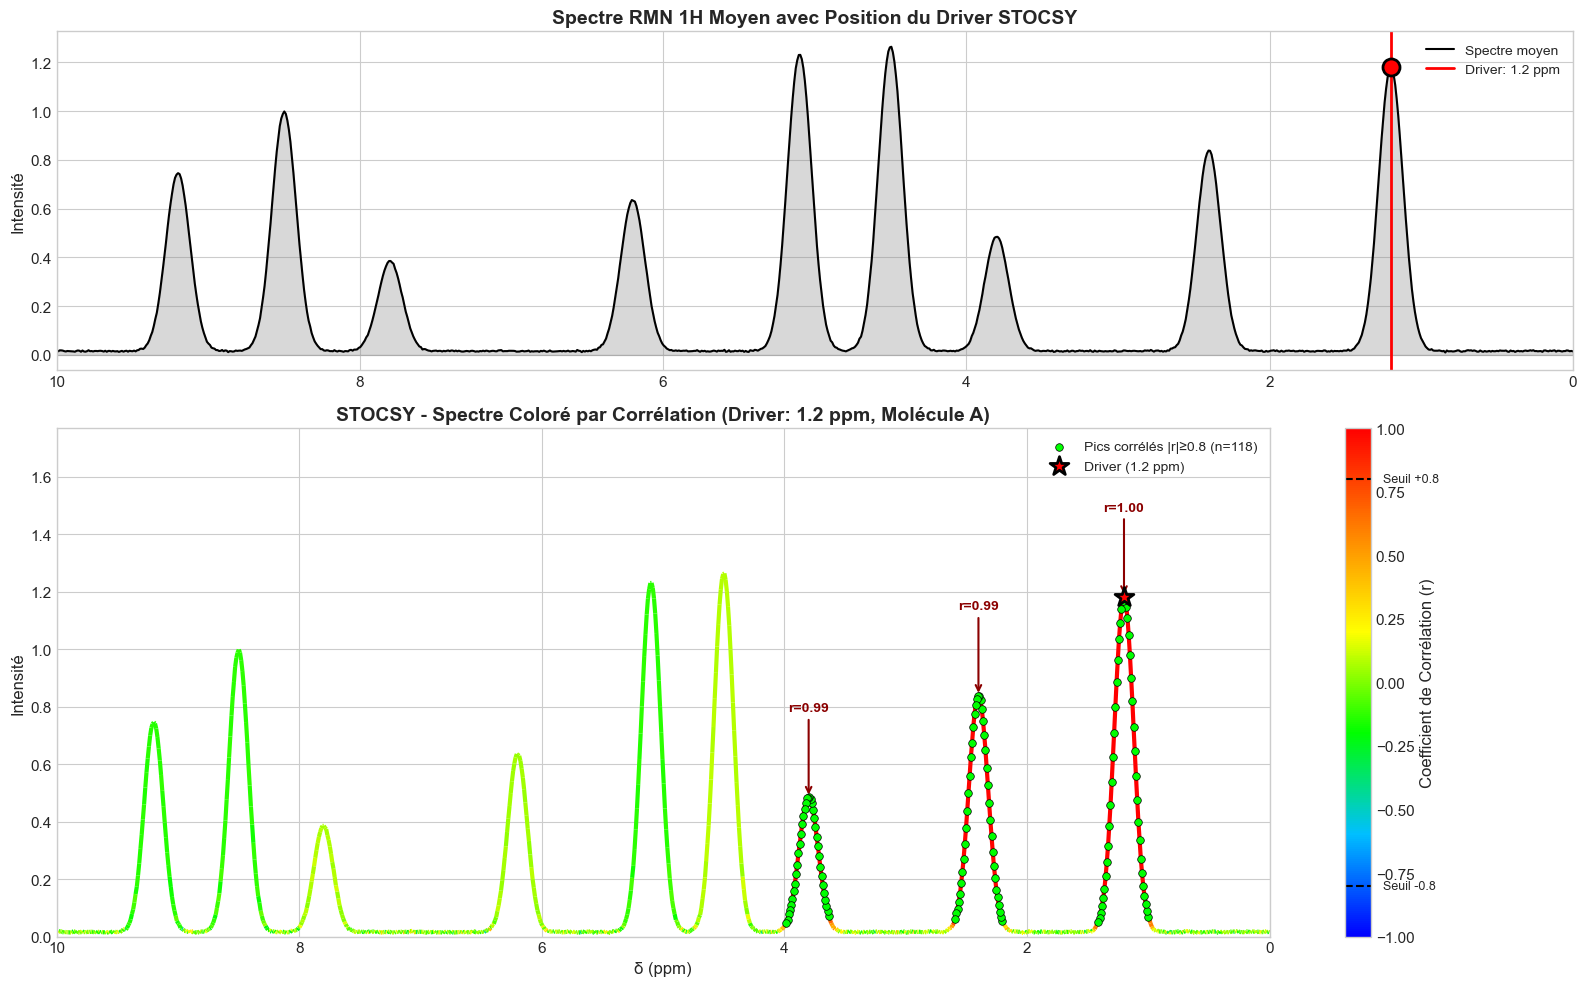

📊 Figure 2: STOCSY montre que les pics à 1.2, 2.4 et 3.8 ppm sont fortement corrélés (Molécule A)


In [19]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10), gridspec_kw={'height_ratios': [1, 1.5]})

# === Subplot 1: Spectre moyen de référence ===
ax1 = axes[0]
ax1.fill_between(ppm_range, 0, mean_spectrum, alpha=0.3, color='gray')
ax1.plot(ppm_range, mean_spectrum, 'k-', linewidth=1.5, label='Spectre moyen')

# Marquer le driver
driver_idx = np.argmin(np.abs(ppm_range - driver_ppm_A))
ax1.axvline(x=driver_ppm_A, color='red', linestyle='-', linewidth=2, label=f'Driver: {driver_ppm_A} ppm')
ax1.scatter([driver_ppm_A], [mean_spectrum[driver_idx]], s=150, c='red', zorder=5, edgecolor='black', linewidth=2)

ax1.set_xlim(0, 10)
ax1.invert_xaxis()
ax1.set_ylabel('Intensité')
ax1.set_title('Spectre RMN 1H Moyen avec Position du Driver STOCSY', fontsize=14, fontweight='bold')
ax1.legend(loc='upper right')

# === Subplot 2: STOCSY coloré par corrélation ===
ax2 = axes[1]

# Créer un tracé coloré par valeur de corrélation
points = np.array([ppm_range, mean_spectrum]).T.reshape(-1, 1, 2)
segments = np.concatenate([points[:-1], points[1:]], axis=1)

from matplotlib.collections import LineCollection
# Normaliser les corrélations pour la colormap
norm = plt.Normalize(-1, 1)
lc = LineCollection(segments, cmap=stocsy_cmap, norm=norm)
lc.set_array(correlations_A[:-1])
lc.set_linewidth(3)
line = ax2.add_collection(lc)

# Colorbar
cbar = plt.colorbar(line, ax=ax2, label='Coefficient de Corrélation (r)')
cbar.ax.axhline(y=0.8, color='black', linestyle='--', linewidth=1.5)
cbar.ax.axhline(y=-0.8, color='black', linestyle='--', linewidth=1.5)
cbar.ax.text(1.5, 0.8, 'Seuil +0.8', fontsize=9, va='center')
cbar.ax.text(1.5, -0.8, 'Seuil -0.8', fontsize=9, va='center')

# Marquer les pics significatifs
significant_ppms = ppm_range[significant_A]
significant_ints = mean_spectrum[significant_A]
ax2.scatter(significant_ppms, significant_ints, c='lime', s=30, zorder=5, 
           edgecolor='black', linewidth=0.5, label=f'Pics corrélés |r|≥0.8 (n={len(significant_ppms)})')

# Marquer le driver
ax2.scatter([driver_ppm_A], [mean_spectrum[driver_idx]], s=200, c='red', zorder=6,
           edgecolor='black', linewidth=2, marker='*', label=f'Driver ({driver_ppm_A} ppm)')

# Annotations pour les pics de la Molécule A
for peak in molecules['Molécule A']['peaks']:
    peak_idx = np.argmin(np.abs(ppm_range - peak))
    r_val = correlations_A[peak_idx]
    ax2.annotate(f'r={r_val:.2f}', xy=(peak, mean_spectrum[peak_idx]),
                xytext=(peak, mean_spectrum[peak_idx] + 0.3),
                fontsize=10, ha='center', color='darkred', fontweight='bold',
                arrowprops=dict(arrowstyle='->', color='darkred', lw=1.5))

ax2.set_xlim(0, 10)
ax2.set_ylim(0, max(mean_spectrum) * 1.4)
ax2.invert_xaxis()
ax2.set_xlabel('δ (ppm)')
ax2.set_ylabel('Intensité')
ax2.set_title(f'STOCSY - Spectre Coloré par Corrélation (Driver: {driver_ppm_A} ppm, Molécule A)', 
             fontsize=14, fontweight='bold')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.savefig('figures/02_stocsy_visualization.png', dpi=150, bbox_inches='tight')
plt.show()

print("📊 Figure 2: STOCSY montre que les pics à 1.2, 2.4 et 3.8 ppm sont fortement corrélés (Molécule A)")

## 5. Matrice de Corrélation STOCSY (Heatmap)

Visualisation de la matrice de corrélation complète entre tous les pics d'intérêt.
Les clusters de corrélation élevée identifient les groupes de pics appartenant à la même molécule.

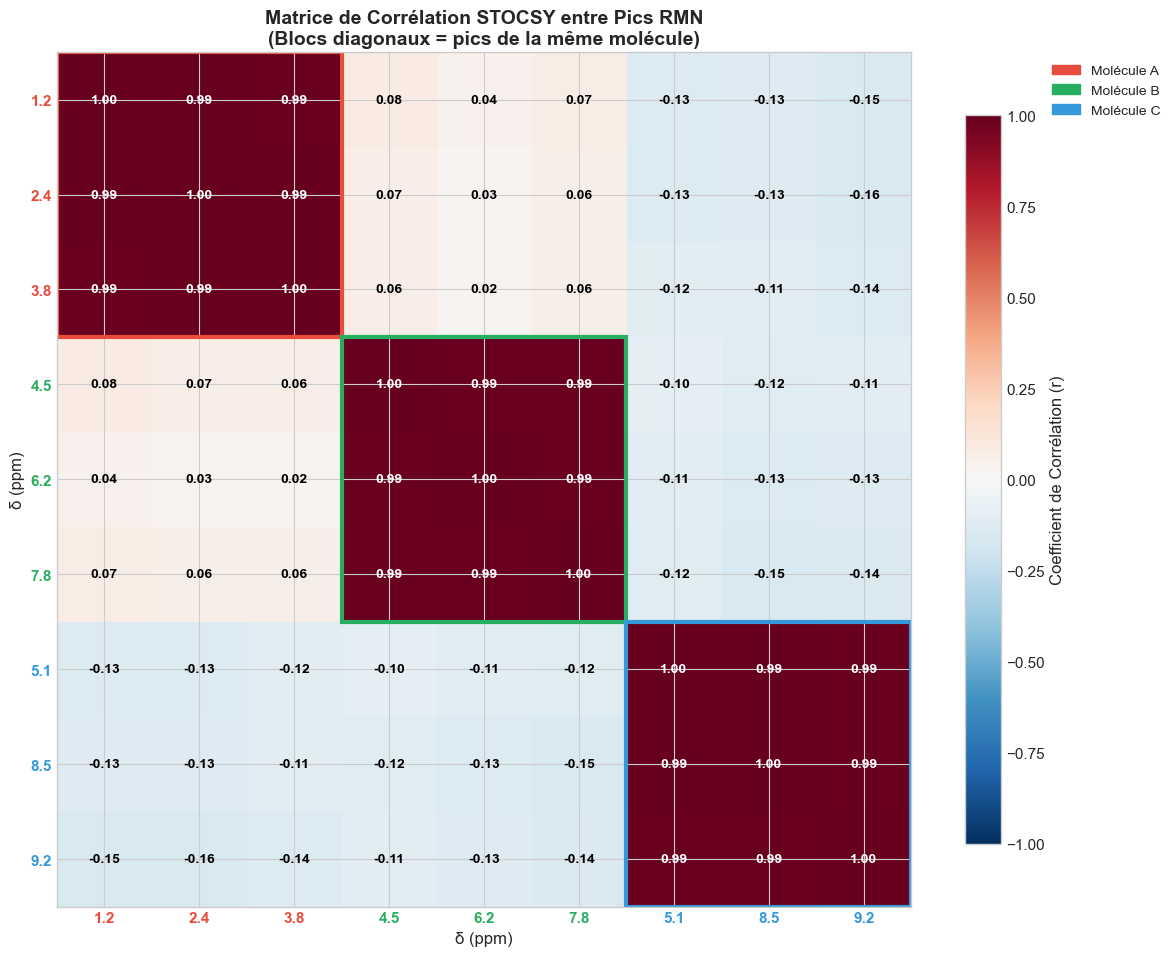

📊 Figure 3: Les blocs diagonaux rouges (r ≈ 1) montrent les pics de la même molécule
   Les pics inter-molécules ont des corrélations proches de 0


In [20]:
# Extraire les indices des pics d'intérêt (tous les pics des 3 molécules)
all_peaks = []
peak_labels = []
peak_colors = []
for mol_name, mol_data in molecules.items():
    for peak in mol_data['peaks']:
        all_peaks.append(peak)
        peak_labels.append(f'{peak} ppm\n({mol_name[:3]})')
        peak_colors.append(mol_data['color'])

# Trouver les indices dans la matrice spectrale
peak_indices = [np.argmin(np.abs(ppm_range - p)) for p in all_peaks]

# Extraire les signaux pour ces pics
peak_signals = spectrum_matrix[:, peak_indices]

# Calculer la matrice de corrélation
corr_matrix = np.corrcoef(peak_signals.T)

# Visualisation
fig, ax = plt.subplots(figsize=(12, 10))

# Heatmap avec annotations
mask = np.zeros_like(corr_matrix, dtype=bool)
np.fill_diagonal(mask, True)  # Masquer la diagonale

im = ax.imshow(corr_matrix, cmap='RdBu_r', vmin=-1, vmax=1, aspect='equal')

# Ajouter les valeurs dans les cellules
for i in range(len(all_peaks)):
    for j in range(len(all_peaks)):
        color = 'white' if abs(corr_matrix[i, j]) > 0.5 else 'black'
        ax.text(j, i, f'{corr_matrix[i, j]:.2f}', ha='center', va='center', 
               fontsize=10, color=color, fontweight='bold')

# Colorbar
cbar = plt.colorbar(im, ax=ax, label='Coefficient de Corrélation (r)', shrink=0.8)

# Labels avec couleurs des molécules
ax.set_xticks(range(len(all_peaks)))
ax.set_yticks(range(len(all_peaks)))
ax.set_xticklabels([f'{p:.1f}' for p in all_peaks], fontsize=11)
ax.set_yticklabels([f'{p:.1f}' for p in all_peaks], fontsize=11)

# Colorer les labels selon la molécule
for idx, (label, color) in enumerate(zip(ax.get_xticklabels(), peak_colors)):
    label.set_color(color)
    label.set_fontweight('bold')
for idx, (label, color) in enumerate(zip(ax.get_yticklabels(), peak_colors)):
    label.set_color(color)
    label.set_fontweight('bold')

# Encadrer les clusters de molécules
# Molécule A: indices 0-2, Molécule B: indices 3-5, Molécule C: indices 6-8
rectangles = [
    ((-0.5, -0.5), 3, 3, '#E74C3C', 'Molécule A'),
    ((2.5, 2.5), 3, 3, '#27AE60', 'Molécule B'),
    ((5.5, 5.5), 3, 3, '#3498DB', 'Molécule C')
]
for (xy, w, h, color, label) in rectangles:
    rect = plt.Rectangle(xy, w, h, fill=False, edgecolor=color, linewidth=3, linestyle='-')
    ax.add_patch(rect)

ax.set_xlabel('δ (ppm)', fontsize=12)
ax.set_ylabel('δ (ppm)', fontsize=12)
ax.set_title('Matrice de Corrélation STOCSY entre Pics RMN\n(Blocs diagonaux = pics de la même molécule)', 
            fontsize=14, fontweight='bold')

# Légende
legend_patches = [mpatches.Patch(color=mol['color'], label=name) 
                  for name, mol in molecules.items()]
ax.legend(handles=legend_patches, loc='upper left', bbox_to_anchor=(1.15, 1))

plt.tight_layout()
plt.savefig('figures/03_stocsy_correlation_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

print("📊 Figure 3: Les blocs diagonaux rouges (r ≈ 1) montrent les pics de la même molécule")
print("   Les pics inter-molécules ont des corrélations proches de 0")

## 6. Effet du Choix du Driver STOCSY

Illustration de l'impact du choix du pic driver sur les résultats STOCSY.
Chaque driver révèle les pics de sa propre molécule.

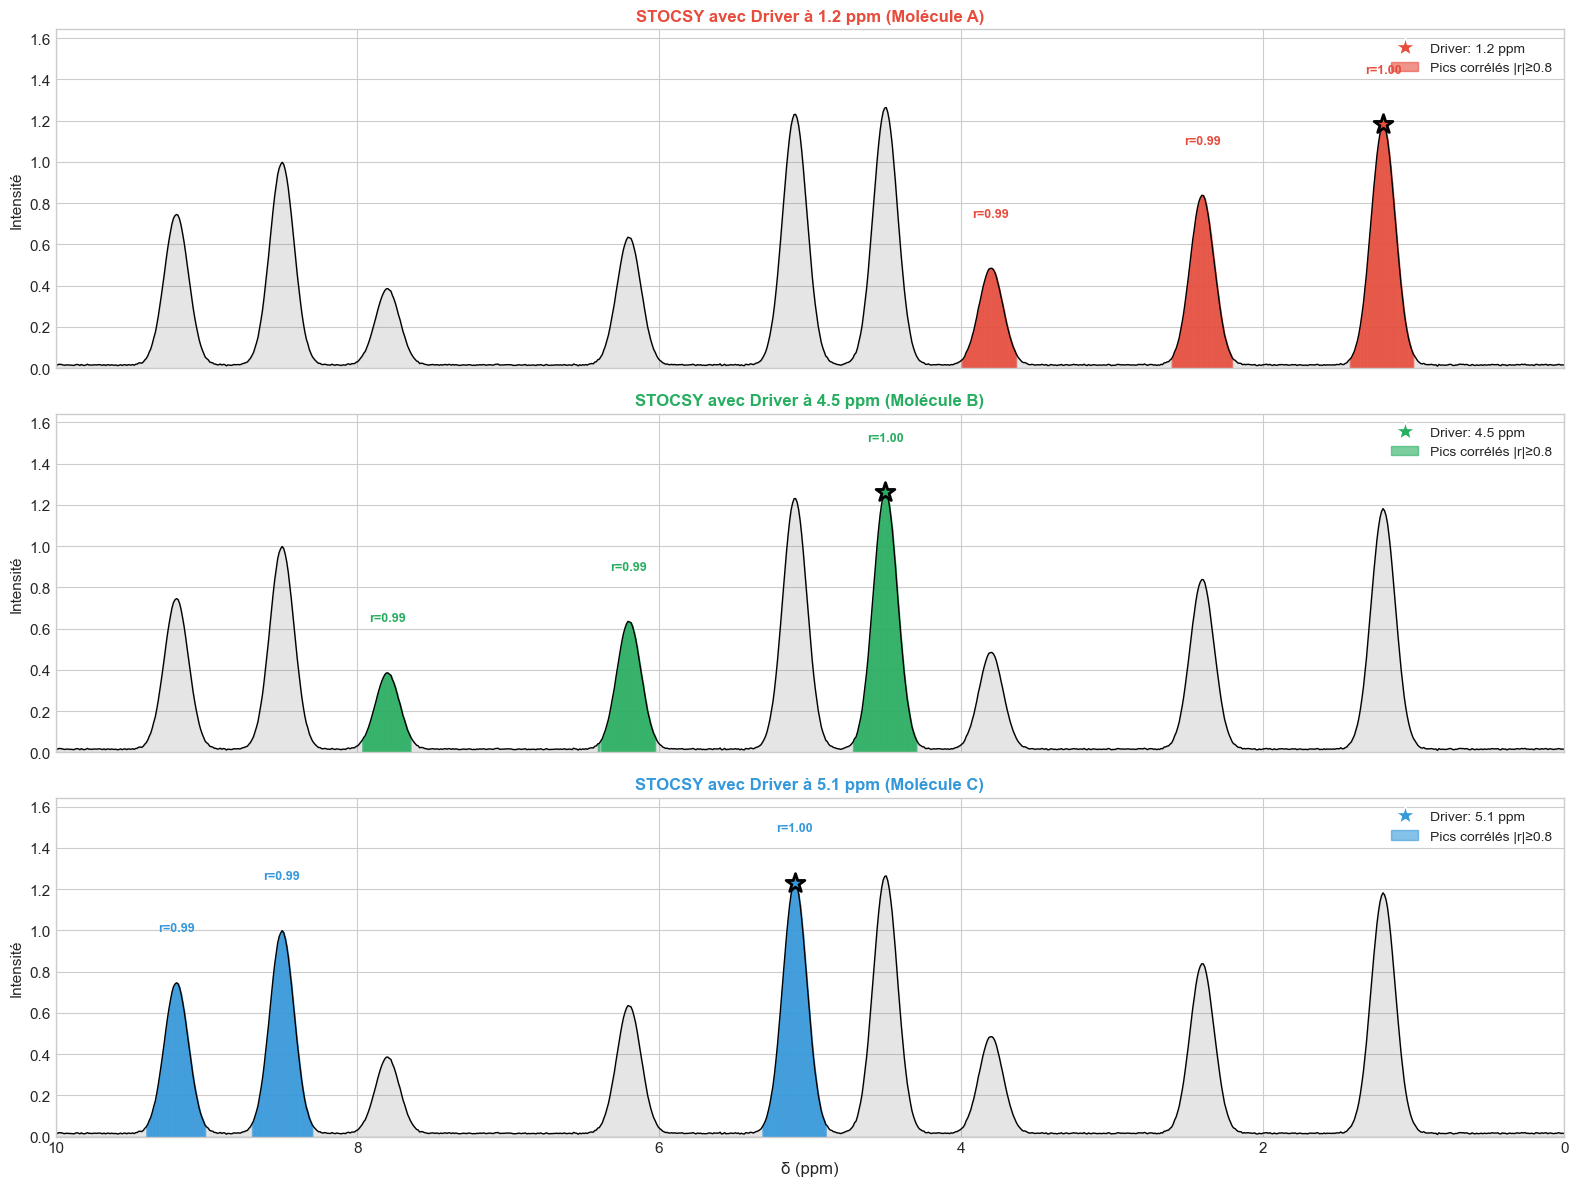

📊 Figure 4: Chaque driver STOCSY révèle uniquement les pics de sa propre molécule


In [21]:
fig, axes = plt.subplots(3, 1, figsize=(16, 12), sharex=True)

# Drivers: un pic de chaque molécule
drivers = [
    (1.2, 'Molécule A', '#E74C3C'),
    (4.5, 'Molécule B', '#27AE60'),
    (5.1, 'Molécule C', '#3498DB')
]

for idx, (driver_ppm, mol_name, color) in enumerate(drivers):
    ax = axes[idx]
    
    # Calculer STOCSY
    correlations, significant = calculate_stocsy(spectrum_matrix, ppm_range, driver_ppm, r_threshold=0.8)
    
    # Tracé du spectre moyen
    ax.fill_between(ppm_range, 0, mean_spectrum, alpha=0.2, color='gray')
    
    # Colorier les régions significatives
    for i in range(len(ppm_range) - 1):
        if significant[i]:
            ax.fill_between([ppm_range[i], ppm_range[i+1]], 0, 
                          [mean_spectrum[i], mean_spectrum[i+1]], 
                          color=color, alpha=0.6)
    
    # Tracer le spectre
    ax.plot(ppm_range, mean_spectrum, 'k-', linewidth=1)
    
    # Marquer le driver
    driver_idx = np.argmin(np.abs(ppm_range - driver_ppm))
    ax.scatter([driver_ppm], [mean_spectrum[driver_idx]], s=200, c=color, 
              zorder=5, edgecolor='black', linewidth=2, marker='*')
    
    # Annotations des pics corrélés
    mol_peaks = molecules[mol_name]['peaks']
    for peak in mol_peaks:
        peak_idx = np.argmin(np.abs(ppm_range - peak))
        r_val = correlations[peak_idx]
        if abs(r_val) >= 0.8:
            ax.annotate(f'r={r_val:.2f}', xy=(peak, mean_spectrum[peak_idx]),
                       xytext=(peak, mean_spectrum[peak_idx] + 0.25),
                       fontsize=9, ha='center', color=color, fontweight='bold')
    
    ax.set_ylabel('Intensité', fontsize=11)
    ax.set_title(f'STOCSY avec Driver à {driver_ppm} ppm ({mol_name})', 
                fontsize=12, fontweight='bold', color=color)
    ax.set_xlim(0, 10)
    ax.invert_xaxis()
    ax.set_ylim(0, max(mean_spectrum) * 1.3)
    
    # Légende
    legend_elements = [
        plt.Line2D([0], [0], marker='*', color='w', markerfacecolor=color, 
                  markersize=15, label=f'Driver: {driver_ppm} ppm'),
        mpatches.Patch(color=color, alpha=0.6, label=f'Pics corrélés |r|≥0.8')
    ]
    ax.legend(handles=legend_elements, loc='upper right')

axes[-1].set_xlabel('δ (ppm)', fontsize=12)

plt.tight_layout()
plt.savefig('figures/04_stocsy_driver_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("📊 Figure 4: Chaque driver STOCSY révèle uniquement les pics de sa propre molécule")

## 7. RANSY - Implémentation et Visualisation

### Principe RANSY
La méthode RANSY analyse la **stabilité des ratios d'intensité** entre pics à travers les échantillons.

Pour deux pics appartenant à la même molécule, le ratio d'intensité reste constant :

$$\text{Ratio}_{i,j} = \frac{I_{\text{pic}_j}}{I_{\text{driver}}} \quad \forall \text{ échantillons}$$

On mesure la stabilité via le **Coefficient de Variation (CV)** :

$$CV = \frac{\sigma_{\text{ratio}}}{\mu_{\text{ratio}}}$$

**Interprétation:**
- $CV < 0.05$ (5%) → Ratio très stable (même molécule)
- $CV > 0.20$ (20%) → Ratio instable (molécules différentes)

Le code R correspondant (`calculer_RANSY`) implémente cette logique.

In [22]:
def calculate_ransy(spectrum_matrix, ppm_range, driver_ppm, cv_threshold=0.05):
    """
    Calcule RANSY à partir d'un pic driver.
    
    Paramètres:
    -----------
    spectrum_matrix : np.array (n_samples, n_points)
        Matrice d'intensité spectrale
    ppm_range : np.array
        Valeurs ppm correspondantes
    driver_ppm : float
        Position ppm du pic driver (référence pour les ratios)
    cv_threshold : float
        Seuil CV maximum pour considérer un ratio comme stable
    
    Retourne:
    ---------
    cv_values : np.array
        Coefficient de variation pour chaque point ppm
    stable_mask : np.array (bool)
        Masque des pics avec ratio stable
    ratio_means : np.array
        Moyenne des ratios pour chaque pic
    """
    # Trouver l'indice du driver
    driver_idx = np.argmin(np.abs(ppm_range - driver_ppm))
    driver_intensities = spectrum_matrix[:, driver_idx]
    
    # Éviter division par zéro
    valid_samples = driver_intensities > 0.01
    
    # Calculer les ratios et CV pour chaque point
    cv_values = np.full(len(ppm_range), np.inf)
    ratio_means = np.zeros(len(ppm_range))
    
    for i in range(len(ppm_range)):
        intensities = spectrum_matrix[valid_samples, i]
        drivers = driver_intensities[valid_samples]
        
        if len(intensities) > 2 and np.all(drivers > 0):
            ratios = intensities / drivers
            ratio_mean = np.mean(ratios)
            ratio_std = np.std(ratios)
            
            if ratio_mean > 0:
                cv_values[i] = ratio_std / ratio_mean
                ratio_means[i] = ratio_mean
    
    # Masque des pics stables
    stable_mask = cv_values <= cv_threshold
    
    return cv_values, stable_mask, ratio_means

# Appliquer RANSY avec le pic à 1.2 ppm (Molécule A) comme driver
driver_ppm_A = 1.2
cv_values_A, stable_A, ratio_means_A = calculate_ransy(spectrum_matrix, ppm_range, driver_ppm_A, cv_threshold=0.05)

print(f"✅ RANSY calculé avec driver à {driver_ppm_A} ppm (Molécule A)")
print(f"   Pics avec CV ≤ 5%: {stable_A.sum()} points")

✅ RANSY calculé avec driver à 1.2 ppm (Molécule A)
   Pics avec CV ≤ 5%: 45 points


### 🔬 Principe Fondamental de RANSY: La Stabilité des Ratios

**Idée clé:** Pour des pics appartenant à la **même molécule**, le **ratio d'intensité reste CONSTANT** d'un échantillon à l'autre :

$$\frac{I_{\text{pic}_2}}{I_{\text{pic}_1}} = \text{constante} \quad \forall \text{ échantillons}$$

**Pourquoi?** Les ratios d'intensité reflètent le **nombre relatif de protons** dans chaque environnement chimique de la molécule. Ce ratio est une propriété **intrinsèque** de la structure moléculaire, indépendante de la concentration.

- 🧪 **Même molécule:** Si pic₁ a 3H et pic₂ a 2H → ratio ≈ 2/3 **toujours**
- 🔀 **Molécules différentes:** Ratios varient car concentrations sont **indépendantes**

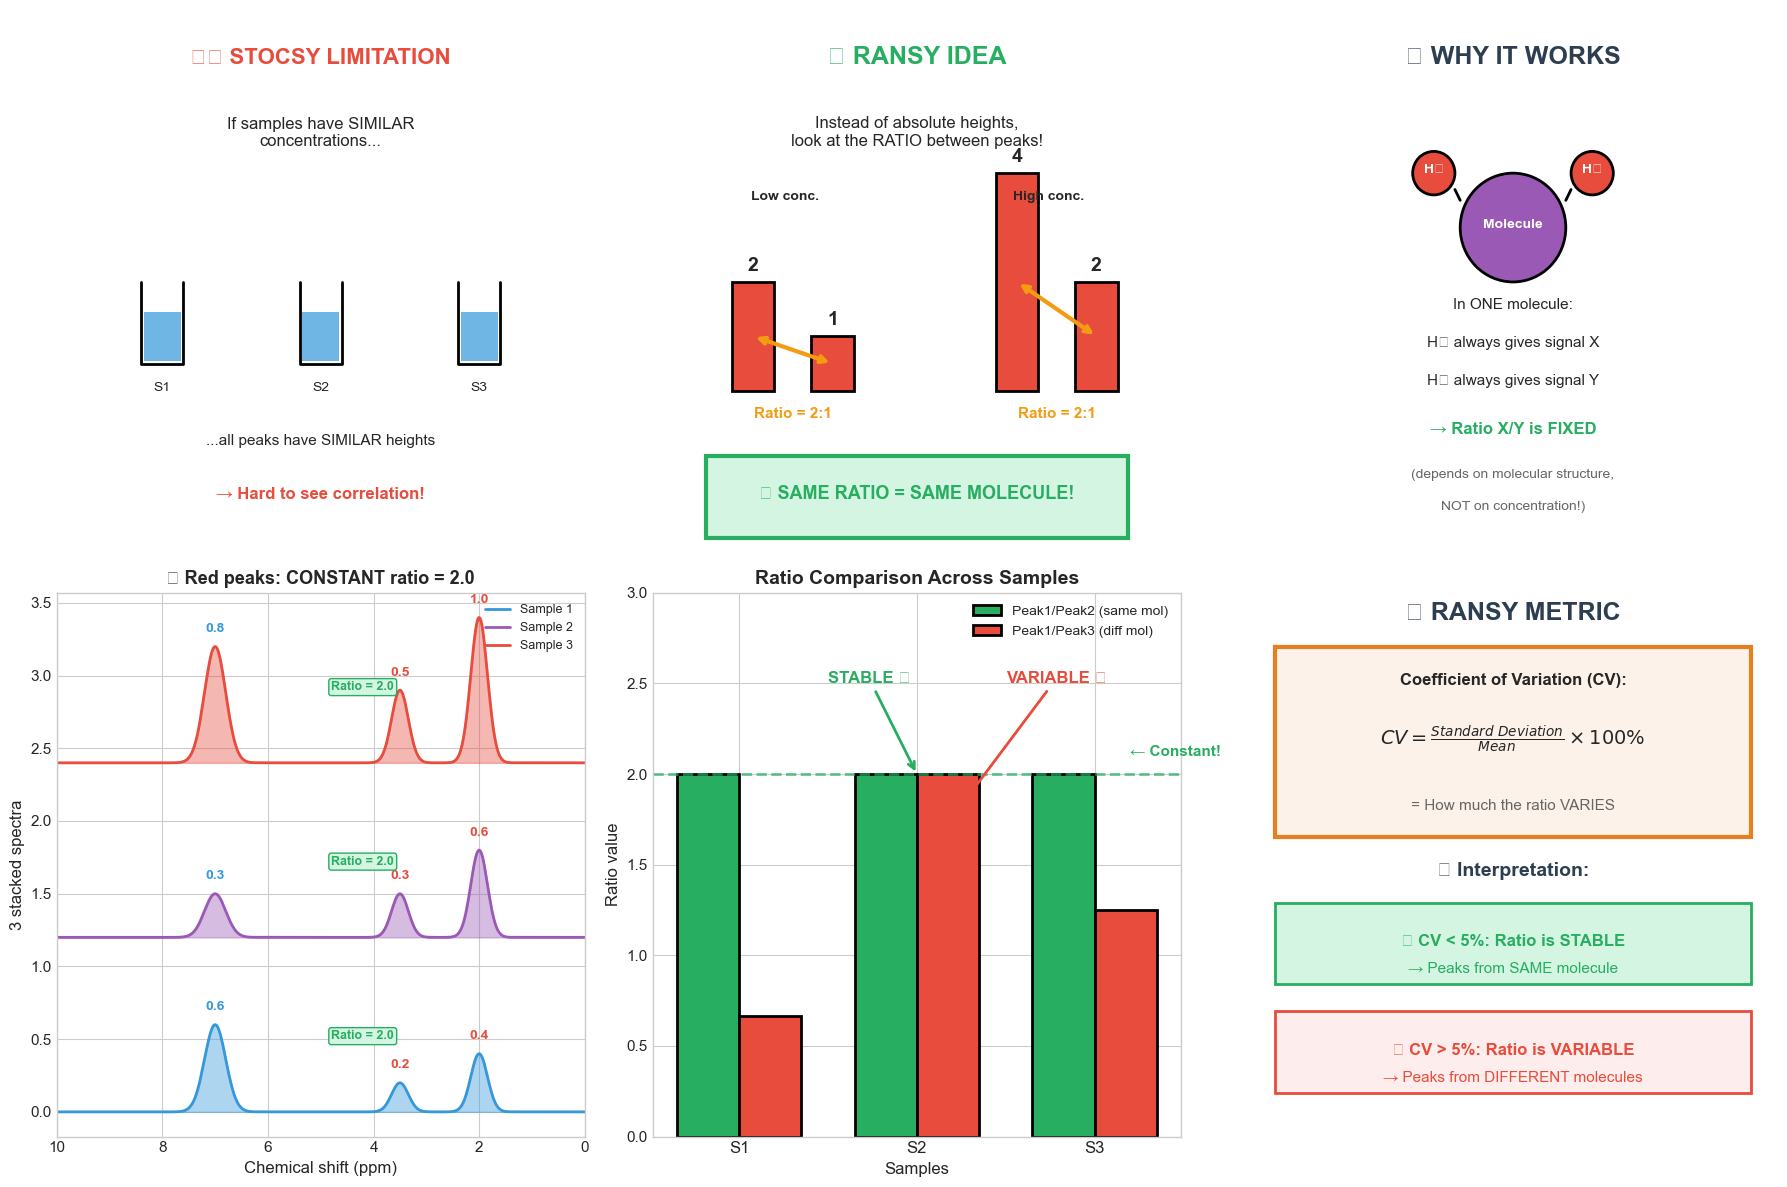


📚 RANSY IN SIMPLE WORDS:
   1. Don't just look at peak HEIGHTS (like STOCSY)
   2. Look at the RATIO between two peak heights
   3. If the ratio stays CONSTANT across samples...
   4. ...the peaks belong to the SAME molecule!
   5. CV measures how stable the ratio is (lower = more stable)


In [33]:
# === ILLUSTRATION SIMPLE ET PÉDAGOGIQUE DE RANSY ===
# Pour quelqu'un qui ne connaît pas du tout le domaine

fig, axes = plt.subplots(2, 3, figsize=(18, 12))

# ========== LIGNE 1: LE CONCEPT ==========

# Panel 1: Le problème de STOCSY
ax1 = axes[0, 0]
ax1.axis('off')
ax1.set_xlim(0, 10)
ax1.set_ylim(0, 10)

ax1.text(5, 9, '⚠️ STOCSY LIMITATION', fontsize=16, fontweight='bold', ha='center', color='#E74C3C')
ax1.text(5, 7.5, 'If samples have SIMILAR\nconcentrations...', fontsize=12, ha='center')

# 3 béchers similaires
for x, label in zip([2, 5, 8], ['S1', 'S2', 'S3']):
    ax1.plot([x-0.4, x-0.4, x+0.4, x+0.4], [5, 3.5, 3.5, 5], 'k-', linewidth=2)
    rect = plt.Rectangle((x-0.35, 3.55), 0.7, 0.9, facecolor='#3498DB', alpha=0.7)
    ax1.add_patch(rect)
    ax1.text(x, 3, label, fontsize=10, ha='center')

ax1.text(5, 2, '...all peaks have SIMILAR heights', fontsize=11, ha='center')
ax1.text(5, 1, '→ Hard to see correlation!', fontsize=12, ha='center', color='#E74C3C', fontweight='bold')

# Panel 2: L'idée RANSY
ax2 = axes[0, 1]
ax2.axis('off')
ax2.set_xlim(0, 10)
ax2.set_ylim(0, 10)

ax2.text(5, 9, '💡 RANSY IDEA', fontsize=18, fontweight='bold', ha='center', color='#27AE60')
ax2.text(5, 7.5, 'Instead of absolute heights,\nlook at the RATIO between peaks!', fontsize=12, ha='center')

# Illustration: 2 barres avec ratio
# Faible concentration
ax2.text(2.5, 6.5, 'Low conc.', fontsize=10, ha='center', fontweight='bold')
rect1 = plt.Rectangle((1.5, 3), 0.8, 2, facecolor='#E74C3C', edgecolor='black', linewidth=2)
rect2 = plt.Rectangle((3, 3), 0.8, 1, facecolor='#E74C3C', edgecolor='black', linewidth=2)
ax2.add_patch(rect1)
ax2.add_patch(rect2)
ax2.text(1.9, 5.2, '2', fontsize=14, ha='center', fontweight='bold')
ax2.text(3.4, 4.2, '1', fontsize=14, ha='center', fontweight='bold')
ax2.annotate('', xy=(3.4, 3.5), xytext=(1.9, 4),
            arrowprops=dict(arrowstyle='<->', color='#F39C12', lw=3))
ax2.text(2.65, 2.5, 'Ratio = 2:1', fontsize=11, ha='center', color='#F39C12', fontweight='bold')

# Forte concentration
ax2.text(7.5, 6.5, 'High conc.', fontsize=10, ha='center', fontweight='bold')
rect3 = plt.Rectangle((6.5, 3), 0.8, 4, facecolor='#E74C3C', edgecolor='black', linewidth=2)
rect4 = plt.Rectangle((8, 3), 0.8, 2, facecolor='#E74C3C', edgecolor='black', linewidth=2)
ax2.add_patch(rect3)
ax2.add_patch(rect4)
ax2.text(6.9, 7.2, '4', fontsize=14, ha='center', fontweight='bold')
ax2.text(8.4, 5.2, '2', fontsize=14, ha='center', fontweight='bold')
ax2.annotate('', xy=(8.4, 4), xytext=(6.9, 5),
            arrowprops=dict(arrowstyle='<->', color='#F39C12', lw=3))
ax2.text(7.65, 2.5, 'Ratio = 2:1', fontsize=11, ha='center', color='#F39C12', fontweight='bold')

# Encadré conclusion
rect_key = plt.Rectangle((1, 0.3), 8, 1.5, facecolor='#D5F5E3', edgecolor='#27AE60', linewidth=3)
ax2.add_patch(rect_key)
ax2.text(5, 1.0, '✓ SAME RATIO = SAME MOLECULE!', fontsize=13, ha='center', fontweight='bold', color='#27AE60')

# Panel 3: Pourquoi ça marche
ax3 = axes[0, 2]
ax3.axis('off')
ax3.set_xlim(0, 10)
ax3.set_ylim(0, 10)

ax3.text(5, 9, '🧠 WHY IT WORKS', fontsize=18, fontweight='bold', ha='center', color='#2C3E50')

# Molécule avec 2 H
circle_mol = plt.Circle((5, 6), 1, facecolor='#9B59B6', edgecolor='black', linewidth=2)
ax3.add_patch(circle_mol)
ax3.text(5, 6, 'Molecule', fontsize=10, ha='center', color='white', fontweight='bold')

# H1 et H2
circle_h1 = plt.Circle((3.5, 7), 0.4, facecolor='#E74C3C', edgecolor='black', linewidth=2)
circle_h2 = plt.Circle((6.5, 7), 0.4, facecolor='#E74C3C', edgecolor='black', linewidth=2)
ax3.add_patch(circle_h1)
ax3.add_patch(circle_h2)
ax3.text(3.5, 7, 'H₁', fontsize=10, ha='center', color='white', fontweight='bold')
ax3.text(6.5, 7, 'H₂', fontsize=10, ha='center', color='white', fontweight='bold')
ax3.plot([4, 3.9], [6.5, 6.7], 'k-', linewidth=2)
ax3.plot([6, 6.1], [6.5, 6.7], 'k-', linewidth=2)

ax3.text(5, 4.5, 'In ONE molecule:', fontsize=11, ha='center')
ax3.text(5, 3.8, 'H₁ always gives signal X', fontsize=11, ha='center')
ax3.text(5, 3.1, 'H₂ always gives signal Y', fontsize=11, ha='center')

rect_formula = plt.Rectangle((1.5, 0.5), 7, 2), 
ax3.text(5, 2.2, '→ Ratio X/Y is FIXED', fontsize=12, ha='center', fontweight='bold', color='#27AE60')
ax3.text(5, 1.4, '(depends on molecular structure,', fontsize=10, ha='center', color='#666')
ax3.text(5, 0.8, 'NOT on concentration!)', fontsize=10, ha='center', color='#666')

# ========== LIGNE 2: LA DÉMONSTRATION ==========

# Panel 4: Exemple avec spectres
ax4 = axes[1, 0]

# 3 spectres avec ratios constants pour Mol A
ppm_simple = np.linspace(0, 10, 500)

# Mol A: pics à 2 et 3 avec ratio fixe 2:1
# Mol B: pic à 7 avec ratio variable par rapport à Mol A
heights_molA_peak1 = [0.4, 0.6, 1.0]  # Pic 1 de Mol A
heights_molA_peak2 = [0.2, 0.3, 0.5]  # Pic 2 de Mol A (ratio fixe 2:1)
heights_molB = [0.6, 0.3, 0.8]  # Mol B (indépendant)

offsets_spec = [0, 1.2, 2.4]
colors_spec = ['#3498DB', '#9B59B6', '#E74C3C']
labels_spec = ['Sample 1', 'Sample 2', 'Sample 3']

for i, (h1, h2, hB, offset, color, label) in enumerate(zip(
    heights_molA_peak1, heights_molA_peak2, heights_molB, offsets_spec, colors_spec, labels_spec)):
    
    spec = offset + h1*np.exp(-((ppm_simple-2)**2)/0.05) + h2*np.exp(-((ppm_simple-3.5)**2)/0.05) + \
           hB*np.exp(-((ppm_simple-7)**2)/0.08)
    ax4.fill_between(ppm_simple, offset, spec, alpha=0.4, color=color)
    ax4.plot(ppm_simple, spec, color=color, linewidth=2, label=label)
    
    # Annoter les hauteurs
    ax4.text(2, offset + h1 + 0.1, f'{h1}', fontsize=10, ha='center', color='#E74C3C', fontweight='bold')
    ax4.text(3.5, offset + h2 + 0.1, f'{h2}', fontsize=10, ha='center', color='#E74C3C', fontweight='bold')
    ax4.text(7, offset + hB + 0.1, f'{hB}', fontsize=10, ha='center', color='#3498DB', fontweight='bold')
    
    # Calculer et annoter le ratio
    ratio_A = h1 / h2
    ax4.text(4.8, offset + 0.5, f'Ratio = {ratio_A:.1f}', fontsize=9, color='#27AE60', fontweight='bold',
            bbox=dict(boxstyle='round,pad=0.2', facecolor='#D5F5E3', edgecolor='#27AE60'))

ax4.set_xlim(0, 10)
ax4.invert_xaxis()
ax4.set_xlabel('Chemical shift (ppm)', fontsize=12)
ax4.set_ylabel('3 stacked spectra', fontsize=12)
ax4.set_title('📊 Red peaks: CONSTANT ratio = 2.0', fontsize=13, fontweight='bold')
ax4.legend(loc='upper right', fontsize=9)

# Panel 5: Comparaison des ratios
ax5 = axes[1, 1]

# Données
samples = ['S1', 'S2', 'S3']
ratios_same = [0.4/0.2, 0.6/0.3, 1.0/0.5]  # Mol A: ratio constant
ratios_diff = [0.4/0.6, 0.6/0.3, 1.0/0.8]  # Mol A vs B: ratio variable

x_pos = np.arange(3)
width = 0.35

bars1 = ax5.bar(x_pos - width/2, ratios_same, width, label='Peak1/Peak2 (same mol)', 
               color='#27AE60', edgecolor='black', linewidth=2)
bars2 = ax5.bar(x_pos + width/2, ratios_diff, width, label='Peak1/Peak3 (diff mol)', 
               color='#E74C3C', edgecolor='black', linewidth=2)

ax5.set_xlabel('Samples', fontsize=12)
ax5.set_ylabel('Ratio value', fontsize=12)
ax5.set_title('Ratio Comparison Across Samples', fontsize=14, fontweight='bold')
ax5.set_xticks(x_pos)
ax5.set_xticklabels(samples, fontsize=12)
ax5.legend(loc='upper right', fontsize=10)
ax5.set_ylim(0, 3)

# Ligne horizontale pour ratio constant
ax5.axhline(y=2.0, color='#27AE60', linestyle='--', linewidth=2, alpha=0.7)
ax5.text(2.2, 2.1, '← Constant!', fontsize=11, color='#27AE60', fontweight='bold')

# Annotations
ax5.annotate('STABLE ✓', xy=(1, 2), xytext=(0.5, 2.5),
            arrowprops=dict(arrowstyle='->', color='#27AE60', lw=2),
            fontsize=12, fontweight='bold', color='#27AE60')
ax5.annotate('VARIABLE ✗', xy=(1, 1.5), xytext=(1.5, 2.5),
            arrowprops=dict(arrowstyle='->', color='#E74C3C', lw=2),
            fontsize=12, fontweight='bold', color='#E74C3C')

# Panel 6: Résumé et formule
ax6 = axes[1, 2]
ax6.axis('off')
ax6.set_xlim(0, 10)
ax6.set_ylim(0, 10)

ax6.text(5, 9.5, '📐 RANSY METRIC', fontsize=18, fontweight='bold', ha='center', color='#2C3E50')

# Formule CV
rect_form = plt.Rectangle((0.5, 5.5), 9, 3.5, facecolor='#FDF2E9', edgecolor='#E67E22', linewidth=3)
ax6.add_patch(rect_form)
ax6.text(5, 8.3, 'Coefficient of Variation (CV):', fontsize=12, ha='center', fontweight='bold')
ax6.text(5, 7.2, r'$CV = \frac{Standard\ Deviation}{Mean} \times 100\%$', fontsize=14, ha='center')
ax6.text(5, 6.0, '= How much the ratio VARIES', fontsize=11, ha='center', color='#666')

# Interprétation
ax6.text(5, 4.8, '🎯 Interpretation:', fontsize=14, ha='center', fontweight='bold', color='#2C3E50')

rect_same = plt.Rectangle((0.5, 2.8), 9, 1.5, facecolor='#D5F5E3', edgecolor='#27AE60', linewidth=2)
ax6.add_patch(rect_same)
ax6.text(5, 3.5, '✓ CV < 5%: Ratio is STABLE', fontsize=12, ha='center', fontweight='bold', color='#27AE60')
ax6.text(5, 3.0, '→ Peaks from SAME molecule', fontsize=11, ha='center', color='#27AE60')

rect_diff = plt.Rectangle((0.5, 0.8), 9, 1.5, facecolor='#FDEDEC', edgecolor='#E74C3C', linewidth=2)
ax6.add_patch(rect_diff)
ax6.text(5, 1.5, '✗ CV > 5%: Ratio is VARIABLE', fontsize=12, ha='center', fontweight='bold', color='#E74C3C')
ax6.text(5, 1.0, '→ Peaks from DIFFERENT molecules', fontsize=11, ha='center', color='#E74C3C')

plt.tight_layout()
plt.savefig('figures/05c_ransy_simple_pedagogique.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n" + "="*70)
print("📚 RANSY IN SIMPLE WORDS:")
print("="*70)
print("   1. Don't just look at peak HEIGHTS (like STOCSY)")
print("   2. Look at the RATIO between two peak heights")
print("   3. If the ratio stays CONSTANT across samples...")
print("   4. ...the peaks belong to the SAME molecule!")
print("   5. CV measures how stable the ratio is (lower = more stable)")

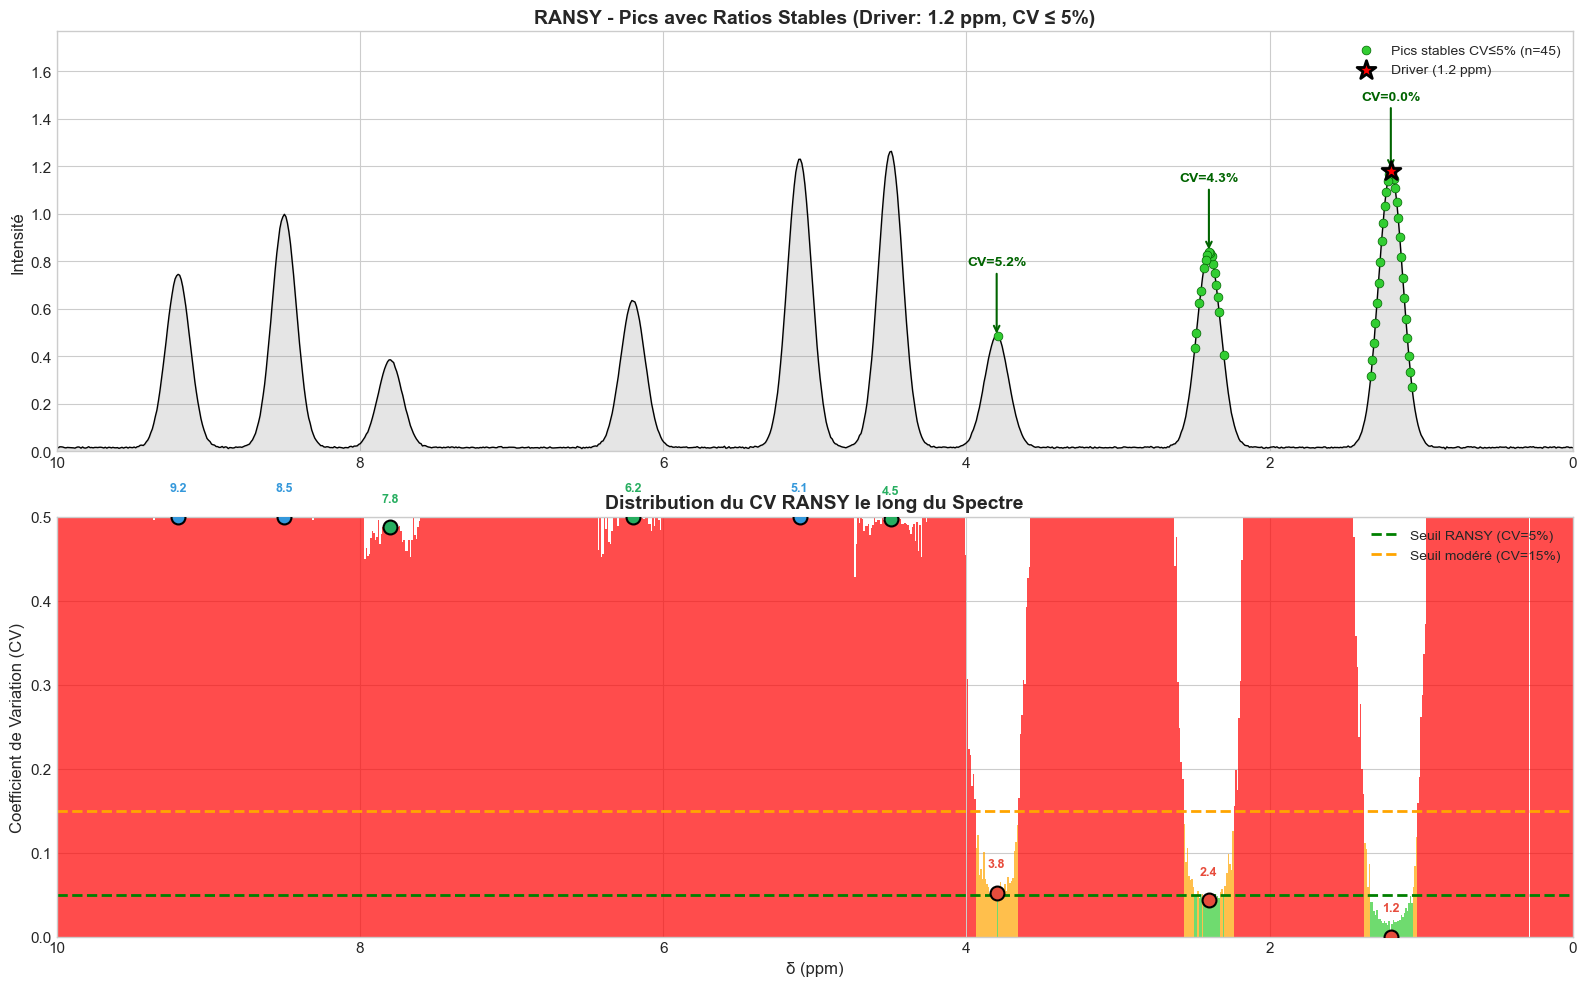

📊 Figure 5: RANSY identifie les pics avec ratios stables (CV faible) = même molécule


In [23]:
fig, axes = plt.subplots(2, 1, figsize=(16, 10), gridspec_kw={'height_ratios': [1, 1]})

# === Subplot 1: Spectre avec pics RANSY validés ===
ax1 = axes[0]

# Fond gris pour le spectre
ax1.fill_between(ppm_range, 0, mean_spectrum, alpha=0.2, color='gray')
ax1.plot(ppm_range, mean_spectrum, 'k-', linewidth=1)

# Colorier les pics stables en vert
stable_ppms = ppm_range[stable_A]
stable_ints = mean_spectrum[stable_A]
ax1.scatter(stable_ppms, stable_ints, c='limegreen', s=40, zorder=5, 
           edgecolor='darkgreen', linewidth=0.5, label=f'Pics stables CV≤5% (n={len(stable_ppms)})')

# Marquer le driver
driver_idx = np.argmin(np.abs(ppm_range - driver_ppm_A))
ax1.scatter([driver_ppm_A], [mean_spectrum[driver_idx]], s=200, c='red', zorder=6,
           edgecolor='black', linewidth=2, marker='*', label=f'Driver ({driver_ppm_A} ppm)')

# Annotations pour les pics de la Molécule A
for peak in molecules['Molécule A']['peaks']:
    peak_idx = np.argmin(np.abs(ppm_range - peak))
    cv_val = cv_values_A[peak_idx]
    ax1.annotate(f'CV={cv_val*100:.1f}%', xy=(peak, mean_spectrum[peak_idx]),
                xytext=(peak, mean_spectrum[peak_idx] + 0.3),
                fontsize=10, ha='center', color='darkgreen', fontweight='bold',
                arrowprops=dict(arrowstyle='->', color='darkgreen', lw=1.5))

ax1.set_xlim(0, 10)
ax1.invert_xaxis()
ax1.set_ylabel('Intensité')
ax1.set_title(f'RANSY - Pics avec Ratios Stables (Driver: {driver_ppm_A} ppm, CV ≤ 5%)', 
             fontsize=14, fontweight='bold')
ax1.legend(loc='upper right')
ax1.set_ylim(0, max(mean_spectrum) * 1.4)

# === Subplot 2: CV en fonction de ppm ===
ax2 = axes[1]

# Limiter CV pour la visualisation
cv_display = np.clip(cv_values_A, 0, 0.5)

# Créer un dégradé de couleur basé sur CV
colors_cv = ['limegreen' if cv <= 0.05 else 'orange' if cv <= 0.15 else 'red' 
             for cv in cv_display]

# Bar plot du CV
ax2.bar(ppm_range, cv_display, width=0.01, color=colors_cv, alpha=0.7)

# Lignes de seuil
ax2.axhline(y=0.05, color='green', linestyle='--', linewidth=2, label='Seuil RANSY (CV=5%)')
ax2.axhline(y=0.15, color='orange', linestyle='--', linewidth=2, label='Seuil modéré (CV=15%)')

# Marquer les pics des molécules
for mol_name, mol_data in molecules.items():
    for peak in mol_data['peaks']:
        peak_idx = np.argmin(np.abs(ppm_range - peak))
        cv_val = min(cv_display[peak_idx], 0.5)
        ax2.scatter([peak], [cv_val], s=100, c=mol_data['color'], zorder=5,
                   edgecolor='black', linewidth=1.5)
        ax2.annotate(f'{peak}', xy=(peak, cv_val), xytext=(peak, cv_val + 0.03),
                    fontsize=9, ha='center', color=mol_data['color'], fontweight='bold')

ax2.set_xlim(0, 10)
ax2.invert_xaxis()
ax2.set_ylim(0, 0.5)
ax2.set_xlabel('δ (ppm)')
ax2.set_ylabel('Coefficient de Variation (CV)')
ax2.set_title('Distribution du CV RANSY le long du Spectre', fontsize=14, fontweight='bold')
ax2.legend(loc='upper right')

plt.tight_layout()
plt.savefig('figures/05_ransy_visualization.png', dpi=150, bbox_inches='tight')
plt.show()

print("📊 Figure 5: RANSY identifie les pics avec ratios stables (CV faible) = même molécule")

## 8. Analyse de Stabilité des Ratios RANSY

Visualisation détaillée de la distribution des ratios d'intensité pour les pics appartenant à la même molécule vs pics de molécules différentes.

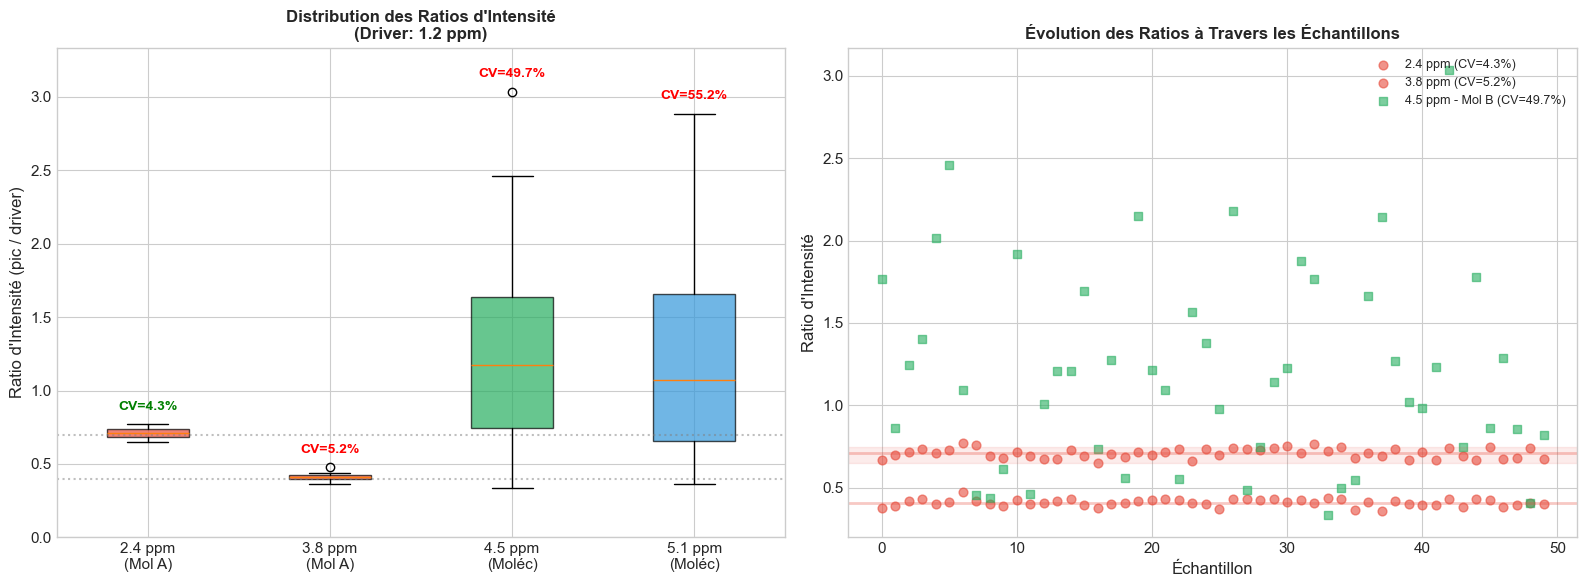

📊 Figure 6: Les pics de la même molécule ont des ratios stables (boîtes étroites)
   Les pics d'autres molécules montrent une grande variabilité (boîtes larges)


In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Driver: 1.2 ppm (Molécule A)
driver_ppm = 1.2
driver_idx = np.argmin(np.abs(ppm_range - driver_ppm))
driver_intensities = spectrum_matrix[:, driver_idx]

# === Subplot 1: Boxplot des ratios ===
ax1 = axes[0]

# Préparer les données pour le boxplot
ratio_data = []
labels = []
colors_box = []

# Pics de la même molécule (A)
for peak in molecules['Molécule A']['peaks'][1:]:  # Exclure le driver lui-même
    peak_idx = np.argmin(np.abs(ppm_range - peak))
    ratios = spectrum_matrix[:, peak_idx] / driver_intensities
    ratio_data.append(ratios)
    labels.append(f'{peak} ppm\n(Mol A)')
    colors_box.append('#E74C3C')

# Pics d'autres molécules (B et C)
for mol_name in ['Molécule B', 'Molécule C']:
    peak = molecules[mol_name]['peaks'][0]  # Premier pic de chaque molécule
    peak_idx = np.argmin(np.abs(ppm_range - peak))
    ratios = spectrum_matrix[:, peak_idx] / driver_intensities
    ratio_data.append(ratios)
    labels.append(f'{peak} ppm\n({mol_name[:5]})')
    colors_box.append(molecules[mol_name]['color'])

bp = ax1.boxplot(ratio_data, patch_artist=True, labels=labels)

for patch, color in zip(bp['boxes'], colors_box):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

# Ajouter les valeurs de CV
for i, data in enumerate(ratio_data):
    cv = np.std(data) / np.mean(data)
    ax1.annotate(f'CV={cv*100:.1f}%', xy=(i+1, np.max(data)), 
                xytext=(i+1, np.max(data) + 0.1),
                fontsize=10, ha='center', fontweight='bold',
                color='green' if cv < 0.05 else 'red')

ax1.axhline(y=0.7, color='gray', linestyle=':', alpha=0.5)  # Ratio attendu pour 2.4 ppm
ax1.axhline(y=0.4, color='gray', linestyle=':', alpha=0.5)  # Ratio attendu pour 3.8 ppm
ax1.set_ylabel('Ratio d\'Intensité (pic / driver)')
ax1.set_title(f'Distribution des Ratios d\'Intensité\n(Driver: {driver_ppm} ppm)', 
             fontsize=12, fontweight='bold')
ax1.set_ylim(0, max([max(d) for d in ratio_data]) + 0.3)

# === Subplot 2: Scatter plot Ratio vs Échantillon ===
ax2 = axes[1]

# Pics de la Molécule A (ratios stables)
for i, peak in enumerate(molecules['Molécule A']['peaks'][1:]):
    peak_idx = np.argmin(np.abs(ppm_range - peak))
    ratios = spectrum_matrix[:, peak_idx] / driver_intensities
    cv = np.std(ratios) / np.mean(ratios)
    ax2.scatter(range(n_samples), ratios, alpha=0.6, s=40, c='#E74C3C',
               label=f'{peak} ppm (CV={cv*100:.1f}%)' if i == 0 else f'{peak} ppm (CV={cv*100:.1f}%)')
    ax2.axhline(y=np.mean(ratios), color='#E74C3C', linestyle='-', alpha=0.3, linewidth=2)

# Pic d'une autre molécule (ratio instable)
peak_other = 4.5  # Molécule B
peak_idx = np.argmin(np.abs(ppm_range - peak_other))
ratios_other = spectrum_matrix[:, peak_idx] / driver_intensities
cv_other = np.std(ratios_other) / np.mean(ratios_other)
ax2.scatter(range(n_samples), ratios_other, alpha=0.6, s=40, c='#27AE60', marker='s',
           label=f'{peak_other} ppm - Mol B (CV={cv_other*100:.1f}%)')

ax2.set_xlabel('Échantillon')
ax2.set_ylabel('Ratio d\'Intensité')
ax2.set_title('Évolution des Ratios à Travers les Échantillons', fontsize=12, fontweight='bold')
ax2.legend(loc='upper right', fontsize=9)

# Zone de stabilité
ax2.axhspan(0.65, 0.75, color='#E74C3C', alpha=0.1, label='Zone stable Mol A')

plt.tight_layout()
plt.savefig('figures/06_ransy_ratio_stability.png', dpi=150, bbox_inches='tight')
plt.show()

print("📊 Figure 6: Les pics de la même molécule ont des ratios stables (boîtes étroites)")
print("   Les pics d'autres molécules montrent une grande variabilité (boîtes larges)")

## 9. Comparaison STOCSY vs RANSY

Comparaison côte à côte des deux méthodes pour identifier les pics d'une même molécule.
Les deux approches sont complémentaires et leur combinaison améliore la fiabilité de l'annotation.

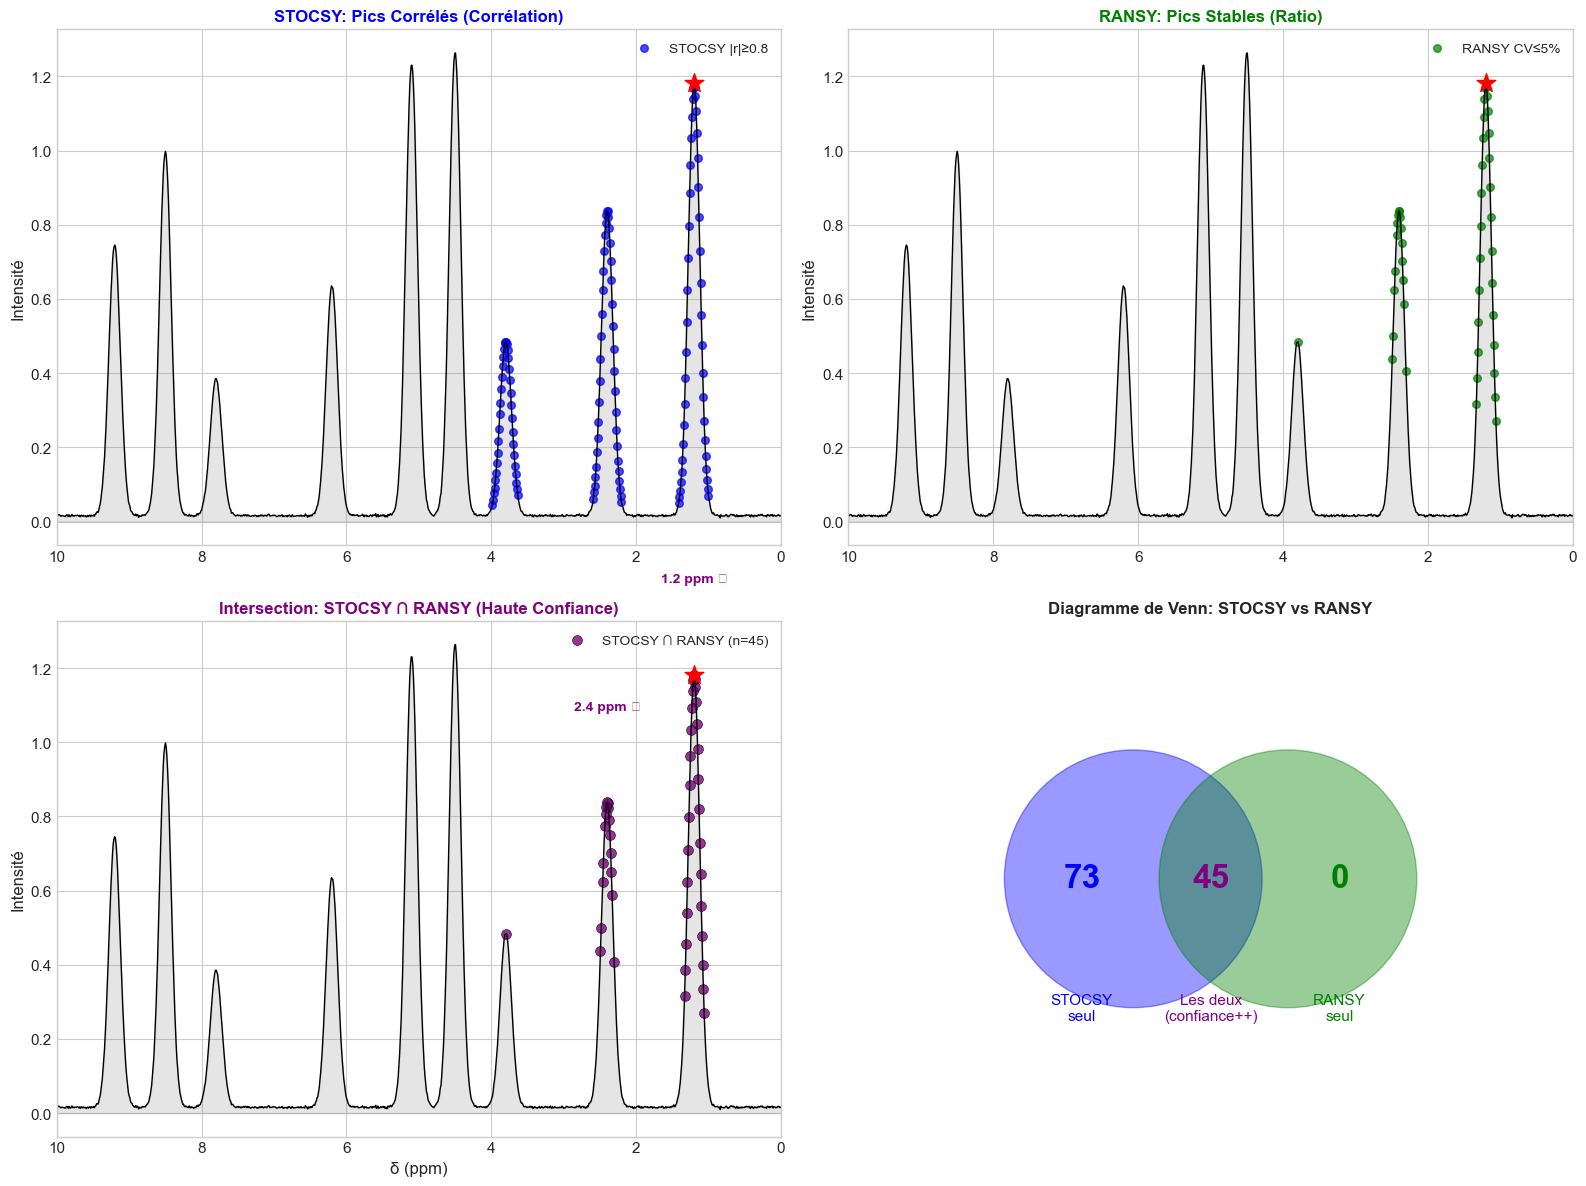

📊 Figure 7: L'intersection STOCSY ∩ RANSY donne les pics les plus fiables
   - STOCSY seul: 73 pics
   - RANSY seul: 0 pics
   - Intersection (haute confiance): 45 pics


In [11]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

driver_ppm = 1.2

# Calculer STOCSY et RANSY
correlations, stocsy_mask = calculate_stocsy(spectrum_matrix, ppm_range, driver_ppm, r_threshold=0.8)
cv_values, ransy_mask, ratio_means = calculate_ransy(spectrum_matrix, ppm_range, driver_ppm, cv_threshold=0.05)

# === Subplot 1: STOCSY ===
ax1 = axes[0, 0]
ax1.fill_between(ppm_range, 0, mean_spectrum, alpha=0.2, color='gray')
ax1.plot(ppm_range, mean_spectrum, 'k-', linewidth=1)

# Pics STOCSY
stocsy_ppms = ppm_range[stocsy_mask]
stocsy_ints = mean_spectrum[stocsy_mask]
ax1.scatter(stocsy_ppms, stocsy_ints, c='blue', s=30, alpha=0.7, label=f'STOCSY |r|≥0.8')

# Driver
driver_idx = np.argmin(np.abs(ppm_range - driver_ppm))
ax1.scatter([driver_ppm], [mean_spectrum[driver_idx]], s=200, c='red', marker='*', zorder=5)

ax1.set_xlim(0, 10)
ax1.invert_xaxis()
ax1.set_ylabel('Intensité')
ax1.set_title('STOCSY: Pics Corrélés (Corrélation)', fontsize=12, fontweight='bold', color='blue')
ax1.legend()

# === Subplot 2: RANSY ===
ax2 = axes[0, 1]
ax2.fill_between(ppm_range, 0, mean_spectrum, alpha=0.2, color='gray')
ax2.plot(ppm_range, mean_spectrum, 'k-', linewidth=1)

# Pics RANSY
ransy_ppms = ppm_range[ransy_mask]
ransy_ints = mean_spectrum[ransy_mask]
ax2.scatter(ransy_ppms, ransy_ints, c='green', s=30, alpha=0.7, label=f'RANSY CV≤5%')

# Driver
ax2.scatter([driver_ppm], [mean_spectrum[driver_idx]], s=200, c='red', marker='*', zorder=5)

ax2.set_xlim(0, 10)
ax2.invert_xaxis()
ax2.set_ylabel('Intensité')
ax2.set_title('RANSY: Pics Stables (Ratio)', fontsize=12, fontweight='bold', color='green')
ax2.legend()

# === Subplot 3: Intersection STOCSY ∩ RANSY ===
ax3 = axes[1, 0]
ax3.fill_between(ppm_range, 0, mean_spectrum, alpha=0.2, color='gray')
ax3.plot(ppm_range, mean_spectrum, 'k-', linewidth=1)

# Intersection
both_mask = stocsy_mask & ransy_mask
both_ppms = ppm_range[both_mask]
both_ints = mean_spectrum[both_mask]
ax3.scatter(both_ppms, both_ints, c='purple', s=50, alpha=0.8, edgecolor='black', linewidth=0.5,
           label=f'STOCSY ∩ RANSY (n={len(both_ppms)})')

# Driver
ax3.scatter([driver_ppm], [mean_spectrum[driver_idx]], s=200, c='red', marker='*', zorder=5)

# Annoter les pics de la Molécule A
for peak in molecules['Molécule A']['peaks']:
    peak_idx = np.argmin(np.abs(ppm_range - peak))
    if both_mask[peak_idx]:
        ax3.annotate(f'{peak} ppm ✓', xy=(peak, mean_spectrum[peak_idx]),
                    xytext=(peak, mean_spectrum[peak_idx] + 0.25),
                    fontsize=10, ha='center', color='purple', fontweight='bold')

ax3.set_xlim(0, 10)
ax3.invert_xaxis()
ax3.set_xlabel('δ (ppm)')
ax3.set_ylabel('Intensité')
ax3.set_title('Intersection: STOCSY ∩ RANSY (Haute Confiance)', fontsize=12, fontweight='bold', color='purple')
ax3.legend()

# === Subplot 4: Diagramme de Venn conceptuel ===
ax4 = axes[1, 1]

# Statistiques
n_stocsy_only = stocsy_mask.sum() - both_mask.sum()
n_ransy_only = ransy_mask.sum() - both_mask.sum()
n_both = both_mask.sum()

# Dessiner des cercles
from matplotlib.patches import Circle
circle1 = Circle((0.35, 0.5), 0.25, color='blue', alpha=0.4, label='STOCSY')
circle2 = Circle((0.65, 0.5), 0.25, color='green', alpha=0.4, label='RANSY')
ax4.add_patch(circle1)
ax4.add_patch(circle2)

# Texte
ax4.text(0.25, 0.5, f'{n_stocsy_only}', fontsize=24, ha='center', va='center', color='blue', fontweight='bold')
ax4.text(0.5, 0.5, f'{n_both}', fontsize=24, ha='center', va='center', color='purple', fontweight='bold')
ax4.text(0.75, 0.5, f'{n_ransy_only}', fontsize=24, ha='center', va='center', color='green', fontweight='bold')

ax4.text(0.25, 0.25, 'STOCSY\nseul', fontsize=11, ha='center', va='center', color='blue')
ax4.text(0.5, 0.25, 'Les deux\n(confiance++)', fontsize=11, ha='center', va='center', color='purple')
ax4.text(0.75, 0.25, 'RANSY\nseul', fontsize=11, ha='center', va='center', color='green')

ax4.set_xlim(0, 1)
ax4.set_ylim(0, 1)
ax4.set_aspect('equal')
ax4.axis('off')
ax4.set_title('Diagramme de Venn: STOCSY vs RANSY', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('figures/07_stocsy_vs_ransy_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("📊 Figure 7: L'intersection STOCSY ∩ RANSY donne les pics les plus fiables")
print(f"   - STOCSY seul: {n_stocsy_only} pics")
print(f"   - RANSY seul: {n_ransy_only} pics")
print(f"   - Intersection (haute confiance): {n_both} pics")

## 10. Pipeline Complet: Match → STOCSY → RANSY

Illustration du pipeline complet utilisé dans `annotation_1H.R`:

1. **Match** : Correspondance des déplacements chimiques prédits avec la matrice spectrale
2. **Tri par Intensité** : Sélection des pivots les plus intenses  
3. **STOCSY** : Filtrage par corrélation (|r| ≥ 0.8)
4. **Filtrage Intensité** : Ratio minimum par rapport au pivot
5. **RANSY** : Validation finale par stabilité des ratios (CV ≤ 5%)
6. **Score Final** : Combinaison coverage + stabilité

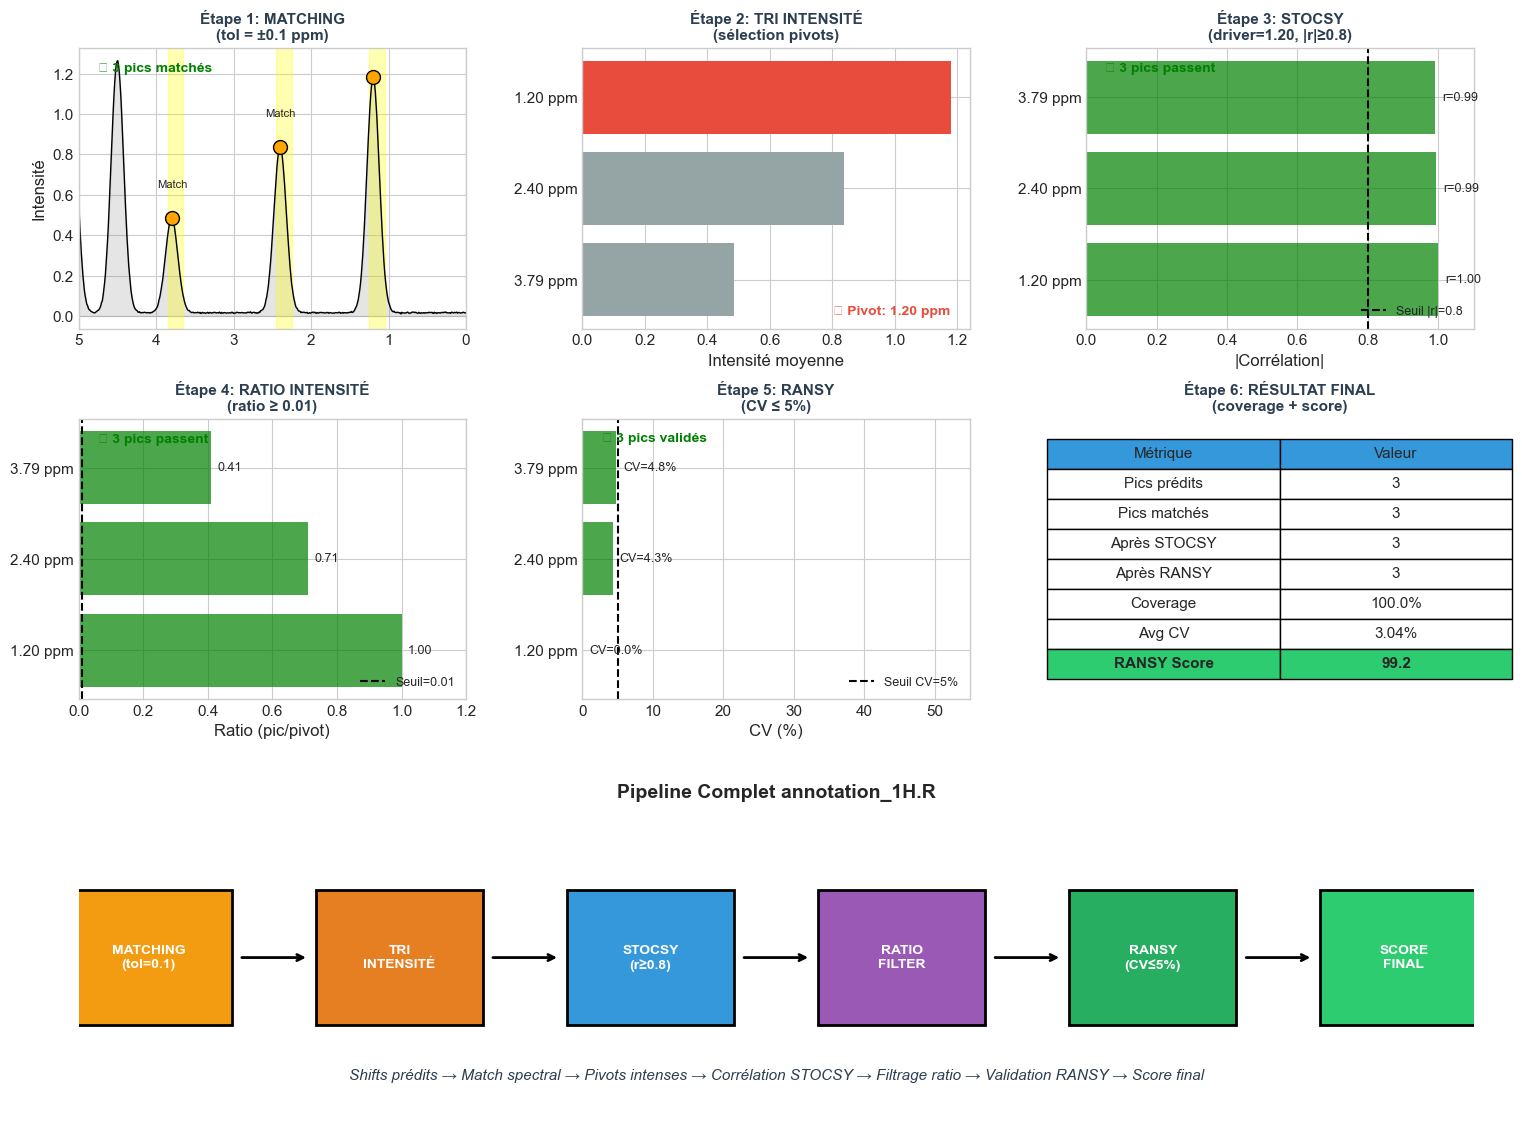

📊 Figure 8: Pipeline complet d'annotation 1H
   Résultat: 3/3 pics validés = 100.0% coverage
   RANSY Score final: 99.2


In [12]:
fig = plt.figure(figsize=(18, 14))

# Créer une grille complexe
gs = fig.add_gridspec(3, 3, height_ratios=[1, 1, 1.2], hspace=0.3, wspace=0.3)

# Paramètres du pipeline (comme dans annotation_1H.R)
tol_match = 0.1
correlation_threshold = 0.80
ratio_min = 0.01
ransy_cv_threshold = 0.05

# Simuler des shifts prédits (molécule A)
predicted_shifts = [1.15, 2.35, 3.75]  # Légèrement décalés pour simuler la prédiction

# === Étape 1: MATCHING ===
ax1 = fig.add_subplot(gs[0, 0])
ax1.set_title('Étape 1: MATCHING\n(tol = ±0.1 ppm)', fontsize=11, fontweight='bold', color='#2C3E50')

# Spectre avec zones de tolérance
ax1.fill_between(ppm_range, 0, mean_spectrum, alpha=0.2, color='gray')
ax1.plot(ppm_range, mean_spectrum, 'k-', linewidth=1)

matched_ppms = []
for pred in predicted_shifts:
    # Zone de tolérance
    ax1.axvspan(pred - tol_match, pred + tol_match, alpha=0.3, color='yellow')
    # Trouver le pic le plus proche dans la matrice
    mask = (ppm_range >= pred - tol_match) & (ppm_range <= pred + tol_match)
    if mask.any():
        best_idx = np.argmax(mean_spectrum[mask])
        matched_ppm = ppm_range[mask][best_idx]
        matched_ppms.append(matched_ppm)
        ax1.scatter([matched_ppm], [mean_spectrum[mask][best_idx]], c='orange', s=100, zorder=5, edgecolor='black')
        ax1.annotate(f'Match', xy=(matched_ppm, mean_spectrum[mask][best_idx] + 0.15), fontsize=8, ha='center')

ax1.set_xlim(0, 5)
ax1.invert_xaxis()
ax1.set_ylabel('Intensité')
n_matched = len(matched_ppms)
ax1.text(0.05, 0.95, f'✓ {n_matched} pics matchés', transform=ax1.transAxes, fontsize=10, 
        verticalalignment='top', color='green', fontweight='bold')

# === Étape 2: TRI PAR INTENSITÉ ===
ax2 = fig.add_subplot(gs[0, 1])
ax2.set_title('Étape 2: TRI INTENSITÉ\n(sélection pivots)', fontsize=11, fontweight='bold', color='#2C3E50')

# Barplot des intensités
intensities = [mean_spectrum[np.argmin(np.abs(ppm_range - p))] for p in matched_ppms]
sorted_idx = np.argsort(intensities)[::-1]
sorted_ppms = [matched_ppms[i] for i in sorted_idx]
sorted_ints = [intensities[i] for i in sorted_idx]

bars = ax2.barh(range(len(sorted_ppms)), sorted_ints, color=['#E74C3C' if i == 0 else '#95A5A6' for i in range(len(sorted_ppms))])
ax2.set_yticks(range(len(sorted_ppms)))
ax2.set_yticklabels([f'{p:.2f} ppm' for p in sorted_ppms])
ax2.set_xlabel('Intensité moyenne')
ax2.invert_yaxis()

pivot_ppm = sorted_ppms[0]
ax2.text(0.95, 0.05, f'★ Pivot: {pivot_ppm:.2f} ppm', transform=ax2.transAxes, fontsize=10, 
        ha='right', color='#E74C3C', fontweight='bold')

# === Étape 3: STOCSY ===
ax3 = fig.add_subplot(gs[0, 2])
ax3.set_title(f'Étape 3: STOCSY\n(driver={pivot_ppm:.2f}, |r|≥{correlation_threshold})', 
             fontsize=11, fontweight='bold', color='#2C3E50')

correlations, stocsy_pass = calculate_stocsy(spectrum_matrix, ppm_range, pivot_ppm, correlation_threshold)

# Afficher les corrélations pour les pics matchés
for ppm in matched_ppms:
    idx = np.argmin(np.abs(ppm_range - ppm))
    r = correlations[idx]
    color = 'green' if abs(r) >= correlation_threshold else 'red'
    ax3.barh(f'{ppm:.2f} ppm', abs(r), color=color, alpha=0.7)
    ax3.text(abs(r) + 0.02, f'{ppm:.2f} ppm', f'r={r:.2f}', va='center', fontsize=9)

ax3.axvline(x=correlation_threshold, color='black', linestyle='--', label=f'Seuil |r|={correlation_threshold}')
ax3.set_xlim(0, 1.1)
ax3.set_xlabel('|Corrélation|')
ax3.legend(loc='lower right', fontsize=9)

stocsy_passed = [p for p in matched_ppms if abs(correlations[np.argmin(np.abs(ppm_range - p))]) >= correlation_threshold]
ax3.text(0.05, 0.95, f'✓ {len(stocsy_passed)} pics passent', transform=ax3.transAxes, fontsize=10, 
        verticalalignment='top', color='green', fontweight='bold')

# === Étape 4: FILTRAGE RATIO ===
ax4 = fig.add_subplot(gs[1, 0])
ax4.set_title(f'Étape 4: RATIO INTENSITÉ\n(ratio ≥ {ratio_min})', fontsize=11, fontweight='bold', color='#2C3E50')

pivot_int = mean_spectrum[np.argmin(np.abs(ppm_range - pivot_ppm))]
ratios = [mean_spectrum[np.argmin(np.abs(ppm_range - p))] / pivot_int for p in stocsy_passed]

for i, (ppm, ratio) in enumerate(zip(stocsy_passed, ratios)):
    color = 'green' if ratio >= ratio_min else 'red'
    ax4.barh(f'{ppm:.2f} ppm', ratio, color=color, alpha=0.7)
    ax4.text(ratio + 0.02, f'{ppm:.2f} ppm', f'{ratio:.2f}', va='center', fontsize=9)

ax4.axvline(x=ratio_min, color='black', linestyle='--', label=f'Seuil={ratio_min}')
ax4.set_xlim(0, 1.2)
ax4.set_xlabel('Ratio (pic/pivot)')
ax4.legend(loc='lower right', fontsize=9)

ratio_passed = [p for p, r in zip(stocsy_passed, ratios) if r >= ratio_min]
ax4.text(0.05, 0.95, f'✓ {len(ratio_passed)} pics passent', transform=ax4.transAxes, fontsize=10, 
        verticalalignment='top', color='green', fontweight='bold')

# === Étape 5: RANSY ===
ax5 = fig.add_subplot(gs[1, 1])
ax5.set_title(f'Étape 5: RANSY\n(CV ≤ {ransy_cv_threshold*100:.0f}%)', fontsize=11, fontweight='bold', color='#2C3E50')

cv_values, ransy_pass, _ = calculate_ransy(spectrum_matrix, ppm_range, pivot_ppm, ransy_cv_threshold)

for ppm in ratio_passed:
    idx = np.argmin(np.abs(ppm_range - ppm))
    cv = cv_values[idx]
    color = 'green' if cv <= ransy_cv_threshold else 'red'
    ax5.barh(f'{ppm:.2f} ppm', min(cv * 100, 50), color=color, alpha=0.7)
    ax5.text(min(cv * 100, 50) + 1, f'{ppm:.2f} ppm', f'CV={cv*100:.1f}%', va='center', fontsize=9)

ax5.axvline(x=ransy_cv_threshold * 100, color='black', linestyle='--', label=f'Seuil CV={ransy_cv_threshold*100:.0f}%')
ax5.set_xlim(0, 55)
ax5.set_xlabel('CV (%)')
ax5.legend(loc='lower right', fontsize=9)

ransy_passed = [p for p in ratio_passed if cv_values[np.argmin(np.abs(ppm_range - p))] <= ransy_cv_threshold]
ax5.text(0.05, 0.95, f'✓ {len(ransy_passed)} pics validés', transform=ax5.transAxes, fontsize=10, 
        verticalalignment='top', color='green', fontweight='bold')

# === Étape 6: RÉSULTAT FINAL ===
ax6 = fig.add_subplot(gs[1, 2])
ax6.set_title('Étape 6: RÉSULTAT FINAL\n(coverage + score)', fontsize=11, fontweight='bold', color='#2C3E50')

# Calculer le coverage
coverage = len(ransy_passed) / len(predicted_shifts) * 100

# Score RANSY (comme dans le code R)
avg_cv = np.mean([cv_values[np.argmin(np.abs(ppm_range - p))] for p in ransy_passed]) if ransy_passed else 1
stability = 1 - min(1, max(0, avg_cv))
ransy_score = 0.75 * coverage + 25 * stability

# Tableau récapitulatif
table_data = [
    ['Pics prédits', len(predicted_shifts)],
    ['Pics matchés', n_matched],
    ['Après STOCSY', len(stocsy_passed)],
    ['Après RANSY', len(ransy_passed)],
    ['Coverage', f'{coverage:.1f}%'],
    ['Avg CV', f'{avg_cv*100:.2f}%'],
    ['RANSY Score', f'{ransy_score:.1f}']
]

ax6.axis('off')
table = ax6.table(cellText=table_data, colLabels=['Métrique', 'Valeur'], 
                  loc='center', cellLoc='center',
                  colColours=['#3498DB', '#3498DB'])
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.2, 1.8)

# Colorer la dernière ligne en vert
for i in range(2):
    table[(len(table_data), i)].set_facecolor('#2ECC71')
    table[(len(table_data), i)].set_text_props(fontweight='bold')

# === FLOWCHART en bas ===
ax_flow = fig.add_subplot(gs[2, :])
ax_flow.set_xlim(0, 10)
ax_flow.set_ylim(0, 2)
ax_flow.axis('off')
ax_flow.set_title('Pipeline Complet annotation_1H.R', fontsize=14, fontweight='bold', y=0.95)

# Dessiner les boîtes du flowchart
boxes = [
    (0.5, 1, 'MATCHING\n(tol=0.1)', '#F39C12'),
    (2.3, 1, 'TRI\nINTENSITÉ', '#E67E22'),
    (4.1, 1, 'STOCSY\n(r≥0.8)', '#3498DB'),
    (5.9, 1, 'RATIO\nFILTER', '#9B59B6'),
    (7.7, 1, 'RANSY\n(CV≤5%)', '#27AE60'),
    (9.5, 1, 'SCORE\nFINAL', '#2ECC71')
]

for x, y, label, color in boxes:
    rect = plt.Rectangle((x-0.6, y-0.4), 1.2, 0.8, facecolor=color, edgecolor='black', linewidth=2)
    ax_flow.add_patch(rect)
    ax_flow.text(x, y, label, ha='center', va='center', fontsize=10, fontweight='bold', color='white')

# Flèches entre les boîtes
for i in range(len(boxes) - 1):
    ax_flow.annotate('', xy=(boxes[i+1][0] - 0.65, boxes[i+1][1]), 
                    xytext=(boxes[i][0] + 0.65, boxes[i][1]),
                    arrowprops=dict(arrowstyle='->', color='black', lw=2))

# Texte descriptif
ax_flow.text(5, 0.3, 
            'Shifts prédits → Match spectral → Pivots intenses → Corrélation STOCSY → Filtrage ratio → Validation RANSY → Score final',
            ha='center', va='center', fontsize=11, style='italic', color='#2C3E50')

plt.savefig('figures/08_complete_pipeline.png', dpi=150, bbox_inches='tight')
plt.show()

print("📊 Figure 8: Pipeline complet d'annotation 1H")
print(f"   Résultat: {len(ransy_passed)}/{len(predicted_shifts)} pics validés = {coverage:.1f}% coverage")
print(f"   RANSY Score final: {ransy_score:.1f}")

## 📚 Résumé et Conclusions

### STOCSY (Statistical TOtal Correlation SpectroscopY)
- **Principe**: Corrélation de Pearson entre pic driver et tous les autres points
- **Avantage**: Détecte les pics co-variant à travers les échantillons
- **Seuil typique**: |r| ≥ 0.80
- **Limite**: Sensible aux faux positifs si concentration co-varie entre molécules

### RANSY (Ratio Analysis of NMR SpectroscopY)  
- **Principe**: Stabilité des ratios d'intensité (CV = σ/μ)
- **Avantage**: Robuste aux variations de concentration globale
- **Seuil typique**: CV ≤ 5%
- **Limite**: Nécessite un signal suffisant au-dessus du bruit

### Combinaison STOCSY + RANSY
La combinaison des deux méthodes dans le pipeline améliore significativement la fiabilité :
- STOCSY filtre par covariance
- RANSY valide par stabilité des ratios
- L'intersection réduit les faux positifs

### Score Final
$$\text{RANSY Score} = 0.75 \times \text{Coverage}(\%) + 25 \times \text{Stabilité}$$

où Stabilité = 1 - CV_moyen (bornée entre 0 et 1)

In [13]:
# Créer le dossier figures s'il n'existe pas
import os
os.makedirs('figures', exist_ok=True)

print("=" * 60)
print("🎉 NOTEBOOK STOCSY/RANSY TERMINÉ")
print("=" * 60)
print("\nFigures générées:")
print("  1. 01_raw_nmr_spectra.png - Spectres bruts superposés")
print("  2. 02_stocsy_visualization.png - STOCSY coloré par corrélation")
print("  3. 03_stocsy_correlation_matrix.png - Matrice de corrélation")
print("  4. 04_stocsy_driver_comparison.png - Effet du choix du driver")
print("  5. 05_ransy_visualization.png - RANSY avec CV")
print("  6. 06_ransy_ratio_stability.png - Stabilité des ratios")
print("  7. 07_stocsy_vs_ransy_comparison.png - Comparaison méthodes")
print("  8. 08_complete_pipeline.png - Pipeline complet")
print("\n📁 Dossier: docs/figures/")
print("\n📝 Ce notebook illustre les méthodes utilisées dans:")
print("   backend/scripts/annotation_1H.R")

🎉 NOTEBOOK STOCSY/RANSY TERMINÉ

Figures générées:
  1. 01_raw_nmr_spectra.png - Spectres bruts superposés
  2. 02_stocsy_visualization.png - STOCSY coloré par corrélation
  3. 03_stocsy_correlation_matrix.png - Matrice de corrélation
  4. 04_stocsy_driver_comparison.png - Effet du choix du driver
  5. 05_ransy_visualization.png - RANSY avec CV
  6. 06_ransy_ratio_stability.png - Stabilité des ratios
  7. 07_stocsy_vs_ransy_comparison.png - Comparaison méthodes
  8. 08_complete_pipeline.png - Pipeline complet

📁 Dossier: docs/figures/

📝 Ce notebook illustre les méthodes utilisées dans:
   backend/scripts/annotation_1H.R
